<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-07/neural-ode.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Neural ordinary differential equations

*Deep Learning for Scientific Discovery, Jagiellonian University. Author Marcin Płodzień.*

Many laws of the natural sciences are differential equations that state how fast each quantity changes given the present state, for example the rates of chemical reactions, the growth and interaction of populations in ecology, the dynamics of gene regulation and physiological control, or the exchange of heat and moisture in climate models. Often the variables can be measured while the law itself is unknown. A neural ODE learns such a law from measured trajectories, and the trained network can then be analysed like a model written down by a scientist.

A neural ordinary differential equation (Neural ODE) is a model of a dynamical system, a system whose state changes in time according to a fixed rule, in which the vector field is a neural network,
$$\dot{\mathbf x}=F_\theta(\mathbf x). \tag{1}$$
The vector field is the function that assigns to every state $\mathbf x$ its rate of change. The network $F_\theta$ receives the state and returns its time derivative. A prediction is obtained by integrating this equation with an ODE solver, a numerical method that advances the state in small time steps, from a measured initial state, and the parameters $\theta$ are fitted so that the integrated trajectory follows the measured one [R. T. Q. Chen, Y. Rubanova, J. Bettencourt, D. Duvenaud, NeurIPS 2018, [arXiv:1806.07366](https://arxiv.org/abs/1806.07366)]. The unknown vector field of equation (1) is thus modelled by a network, and after training $F_\theta$ is the vector field extracted from the data. It is a continuous-time law of motion that can be evaluated at any state and time and analysed with the tools of dynamical systems. Its fixed points are the states at which $F_\theta$ vanishes and the system would stay at rest. Its Jacobian $\partial F_\theta/\partial\mathbf x$, the matrix of first derivatives, decides through its eigenvalues whether a fixed point attracts or repels nearby states, and its trace, the divergence of the field, gives the rate at which a small volume of states shrinks or grows. The largest Lyapunov exponent, the average exponential rate at which two nearby trajectories separate, measures how fast forecasts lose accuracy. All of these quantities are computed from the trained network and compared with those of the true system. A trained network can also be turned into a formula by sparse regression, and we do this for an unknown friction law in the lecture material on the pendulum with unknown friction.

One step of the explicit Euler method has the same form as one block of a residual network, and the limit of small steps turns a residual network into an ODE. We then define the forward pass and the loss of a Neural ODE and compute its gradient in two ways, by differentiating through the steps of the solver and by integrating the adjoint equation backwards in time, and we compare their accuracy, memory and time. In the first of three examples a Neural ODE learns the vector field of a damped pendulum, a pendulum whose swing decays by friction, from noisy trajectories, and we compare the learned field with the true one on the phase plane of angle and angular velocity and forecast beyond the training window. In the second example a Neural ODE learns the Lorenz-63 flow, and we measure how long its forecasts stay close to the truth in units of the Lyapunov time, the time over which a small error grows by the factor $e$. In the third example the pendulum is observed at irregularly spaced times, which a continuous-time model handles directly. We then compare the Neural ODE on the Lorenz data with three discrete-time models fitted to the same samples, a linear autoregressive model (AR), a nonlinear vector autoregression (NVAR) and a multilayer perceptron (MLP) map. Beyond the forecasts, we finally analyse the learned vector field itself, with its fixed points, their stability, its largest Lyapunov exponent and its divergence. The adjoint method with its comparison of memory and time in Section 2 and the irregular sampling of Section 5 go deeper than the lecture, which uses only their main results.

The implementation uses JAX in double precision. Our own fourth-order Runge–Kutta (RK4) integrator, the standard method that advances the state by one step from four evaluations of the vector field, our own adjoint solver and `jax.grad` are compared with the library `diffrax` [P. Kidger, *On Neural Differential Equations*, PhD thesis, University of Oxford (2021), [arXiv:2202.02435](https://arxiv.org/abs/2202.02435)], the optimiser comes from `optax`, and the ridge regressions are checked against scikit-learn.



> **Google Colab execution**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. Execution starts with `JAX_PLATFORMS=cpu`. The calculations took 11.6 minutes in this recorded CPU run. Wall times depend on hardware and concurrent system load.
> 2. `jax`, `optax`, `scikit-learn` and `matplotlib` are pre-installed in Colab. diffrax is installed with `pip install diffrax`.
> 3. Run the cells *in order*. Later cells use variables defined earlier.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch

import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)   # all computations of this notebook in float64
from jax.flatten_util import ravel_pytree
import optax
import diffrax
import sklearn
from sklearn.linear_model import Ridge as SkRidge

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
            "ytick.labelsize": 11, "legend.fontsize": 11, "lines.linewidth": 1.4, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
# one colour and line style per model, used in every figure
STYLE = {"AR": dict(color="0.35", ls="--"), "NVAR": dict(color=DSOrange, ls="--"),
         "MLP map": dict(color="#2A9D8F", ls="-."), "Neural ODE": dict(color="#7B4FA0", ls="-")}
MODELS = ("AR", "NVAR", "MLP map", "Neural ODE")

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    # slide figures are created at their printed size and saved as PDF (slides) and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

def init_mlp(key, sizes):
    # LeCun normal weights (variance 1/n_in) and zero biases, one (W, b) pair per layer
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        key, sub = jax.random.split(key)
        params.append((jax.random.normal(sub, (n_out, n_in)) / np.sqrt(n_in), jnp.zeros(n_out)))
    return params

def mlp(params, x):
    # tanh hidden layers, linear output layer
    for W, b in params[:-1]:
        x = jnp.tanh(W @ x + b)
    W, b = params[-1]
    return W @ x + b

def n_params(params):
    return int(sum(x.size for x in jax.tree.leaves(params)))

def rk4_step(f, y, h):
    # one classical fourth-order Runge-Kutta step for dy/dt = f(y)
    k1 = f(y); k2 = f(y + 0.5 * h * k1); k3 = f(y + 0.5 * h * k2); k4 = f(y + h * k3)
    return y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

def rk4_path(f, y0, h, n_out, sub=1):
    # states after every `sub` RK4 steps of size h, n_out of them (the initial state is not included)
    def one(y, _):
        y = jax.lax.fori_loop(0, sub, lambda i, v: rk4_step(f, v, h), y)
        return y, y
    return jax.lax.scan(one, y0, None, length=n_out)[1]

class RK4(diffrax.AbstractERK):
    """Classical fourth-order Runge-Kutta method as a diffrax solver (Butcher tableau of RK4)."""
    tableau = diffrax.ButcherTableau(c=np.array([0.5, 0.5, 1.0]), b_sol=np.array([1/6, 1/3, 1/3, 1/6]),
                                     b_error=np.zeros(4),
                                     a_lower=(np.array([0.5]), np.array([0.0, 0.5]), np.array([0.0, 0.0, 1.0])))
    interpolation_cls = diffrax.ThirdOrderHermitePolynomialInterpolation.from_k

def train_adam(loss, params, sampler, steps, lr=3e-3, seed=0, clip=1.0, every=100):
    """Adam with gradient clipping and a cosine learning-rate decay; sampler(key) returns one minibatch."""
    tx = optax.chain(optax.clip_by_global_norm(clip), optax.adam(optax.cosine_decay_schedule(lr, steps, alpha=1e-2)))
    state = tx.init(params)
    @jax.jit
    def step(p, s, key):
        l, g = jax.value_and_grad(loss)(p, sampler(key))
        u, s = tx.update(g, s, p)
        return optax.apply_updates(p, u), s, l
    key, hist, t0 = jax.random.key(seed), [], time.time()
    for it in range(steps):
        key, sub = jax.random.split(key)
        params, state, l = step(params, state, sub)
        if it % every == 0:
            hist.append(float(l))
    return params, dict(loss=np.array(hist), time=time.time() - t0, final=float(l))

def timed(fn, *args, repeat=5):
    # median wall time of a compiled function, after one call for compilation
    jax.block_until_ready(fn(*args)); ts = []
    for _ in range(repeat):
        t0 = time.perf_counter(); jax.block_until_ready(fn(*args)); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

nums = {}                 # every number a slide may need, written to the numbers file at the end
t_start = time.time()
print("jax", jax.__version__, "| optax", optax.__version__, "| diffrax", diffrax.__version__, "| scikit-learn", sklearn.__version__)

jax 0.11.0 | optax 0.2.6 | diffrax 0.7.2 | scikit-learn 1.6.1


<hr/>
## 1. Euler steps and residual networks

The explicit Euler method integrates $\dot{\mathbf x}=\mathbf F(\mathbf x)$ by replacing the derivative with a forward difference over the step $\Delta t$,
$$\mathbf x_{k+1}=\mathbf x_k+\Delta t\,\mathbf F(\mathbf x_k). \tag{2}$$
The new state is the old state plus a correction computed from the old state. A residual network (ResNet) has the same structure [K. He, X. Zhang, S. Ren, J. Sun, [arXiv:1512.03385](https://arxiv.org/abs/1512.03385)]. Its hidden representation $\mathbf h_l$ passes from layer $l$ to layer $l+1$ through a block that adds a learned correction to its input,
$$\mathbf h_{l+1}=\mathbf h_l+\mathbf f_l(\mathbf h_l), \tag{3}$$
where $\mathbf f_l$ is a small network with its own parameters. The identity path lets the signal and its gradient pass through many layers, which made networks with more than a hundred layers trainable. Weinan E and, independently, Haber and Ruthotto read the ResNet as an Euler discretisation of a continuous dynamical system, with the layer index playing the role of time [W. E, Commun. Math. Stat. **5**, 1 (2017), [doi:10.1007/s40304-017-0103-z](https://doi.org/10.1007/s40304-017-0103-z); E. Haber, L. Ruthotto, Inverse Probl. **34**, 014004 (2018), [arXiv:1705.03341](https://arxiv.org/abs/1705.03341)].

We write $\mathbf f_l(\mathbf h)=\Delta t\,F_\theta(\mathbf h)$ with a single network $F_\theta$ shared by all layers and let the number of layers grow as $L=T/\Delta t$ with fixed total time $T$. The sequence $\mathbf h_0,\mathbf h_1,\dots,\mathbf h_L$ approaches the solution of
$$\dot{\mathbf x}(t)=F_\theta(\mathbf x(t)),\qquad \mathbf x(0)=\mathbf h_0, \tag{4}$$
at the times $t=l\,\Delta t$. The global error of Euler's method is proportional to $\Delta t$, so the limit exists for a smooth $F_\theta$. In this limit the depth of the network is replaced by the integration time, and any ODE solver can perform the forward pass. A Neural ODE uses this continuous form directly. We check the first-order convergence on the harmonic oscillator $\ddot x=-x$, the idealised frictionless mass on a spring, integrated over one period $T=2\pi$ from $(x,\dot x)=(1,0)$ with decreasing $\Delta t$.

In [2]:
f_ho = lambda y: jnp.array([y[1], -y[0]])          # harmonic oscillator x'' = -x, state (x, v)
def euler_path(f, y0, dt, n):
    # explicit Euler x_{k+1} = x_k + dt f(x_k); returns x_0, ..., x_n
    ys = [np.asarray(y0, float)]
    for _ in range(n):
        ys.append(ys[-1] + dt * np.asarray(f(ys[-1])))
    return np.array(ys)

T_HO = 2 * np.pi
rows_e = []
for dt in (0.5, 0.2, 0.05, 0.01):
    n = int(round(T_HO / dt))
    ys = euler_path(f_ho, [1.0, 0.0], T_HO / n, n)
    err = float(np.linalg.norm(ys[-1] - np.array([1.0, 0.0])))
    rows_e.append(dict(dt=T_HO / n, n=n, err=err, r_end=float(np.linalg.norm(ys[-1]))))
    print(f"dt = {T_HO / n:.4f} ({n:4d} steps): |x_n - x(2 pi)| = {err:.3e}, radius at t = 2 pi {np.linalg.norm(ys[-1]):.4f}")
slopes = np.diff(np.log([r["err"] for r in rows_e])) / np.diff(np.log([r["dt"] for r in rows_e]))
print("local slopes d log(error) / d log(dt):", np.round(slopes, 2))
nums["euler"] = dict(rows=rows_e, slopes=slopes.tolist())

dt = 0.4833 (  13 steps): |x_n - x(2 pi)| = 3.034e+00, radius at t = 2 pi 3.9141
dt = 0.2027 (  31 steps): |x_n - x(2 pi)| = 8.740e-01, radius at t = 2 pi 1.8664
dt = 0.0499 ( 126 steps): |x_n - x(2 pi)| = 1.695e-01, radius at t = 2 pi 1.1694
dt = 0.0100 ( 628 steps): |x_n - x(2 pi)| = 3.193e-02, radius at t = 2 pi 1.0319
local slopes d log(error) / d log(dt): [1.43 1.17 1.04]


Over one period the error of the final state falls from 3.03 at $\Delta t=0.48$ to $3.2\times10^{-2}$ at $\Delta t=0.01$, and the local slope of $\log({\rm error})$ against $\log\Delta t$ approaches one (1.43, 1.17, 1.04), the first-order convergence of Euler's method. The radius $\sqrt{x^2+\dot x^2}$ at $t=2\pi$ is 3.91 for the coarsest step and 1.032 for the finest, against the true value 1. The left part of the figure draws three residual blocks. Each block feeds $\mathbf h_l$ both into the network $\mathbf f_l$ and along the identity path to the sum node, which returns $\mathbf h_{l+1}$. The right panel shows the Euler polygons of the harmonic oscillator in the phase plane $(x,\dot x)$, in which every state of the oscillator is a point, for three step sizes, together with the true orbit, the unit circle.

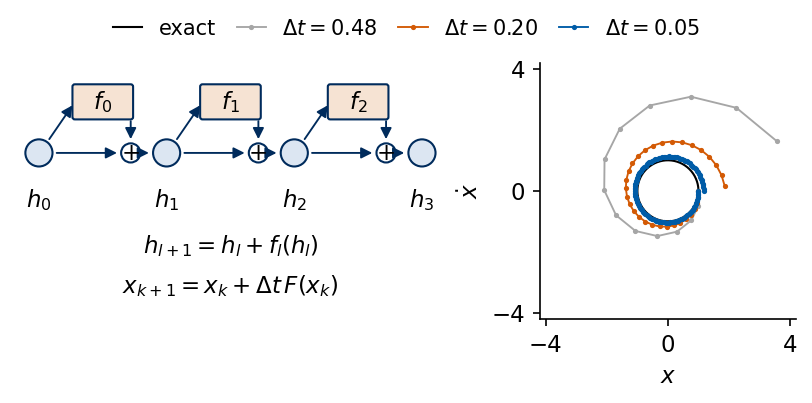

In [3]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.6), layout="constrained", gridspec_kw={"width_ratios": [1.35, 1]})
    ax = axs[0]
    # a stack of three residual blocks h_{l+1} = h_l + f_l(h_l)
    for l in range(3):
        x0 = 1.6 * l
        ax.add_patch(Circle((x0, 0), 0.17, fc="#DCE6F2", ec=UJNavy, lw=1.0, zorder=3))
        ax.text(x0, -0.42, f"$h_{l}$", ha="center", va="top")
        ax.add_patch(FancyBboxPatch((x0 + 0.45, 0.45), 0.7, 0.38, boxstyle="round,pad=0.03", fc="#F6E3D3", ec=UJNavy, lw=1.0, zorder=3))
        ax.text(x0 + 0.8, 0.64, f"$f_{l}$", ha="center", va="center", zorder=4)
        ax.annotate("", xy=(x0 + 0.45, 0.64), xytext=(x0 + 0.1, 0.13), arrowprops=dict(arrowstyle="-|>", color=UJNavy, lw=0.9))
        ax.add_patch(Circle((x0 + 1.15, 0), 0.12, fc="white", ec=UJNavy, lw=1.0, zorder=3))
        ax.text(x0 + 1.15, 0, "+", ha="center", va="center", zorder=4)
        ax.annotate("", xy=(x0 + 1.15, 0.12), xytext=(x0 + 1.15, 0.45), arrowprops=dict(arrowstyle="-|>", color=UJNavy, lw=0.9))
        ax.annotate("", xy=(x0 + 1.03, 0), xytext=(x0 + 0.17, 0), arrowprops=dict(arrowstyle="-|>", color=UJNavy, lw=0.9))
        ax.annotate("", xy=(x0 + 1.43, 0), xytext=(x0 + 1.27, 0), arrowprops=dict(arrowstyle="-|>", color=UJNavy, lw=0.9))
    ax.add_patch(Circle((4.8, 0), 0.17, fc="#DCE6F2", ec=UJNavy, lw=1.0, zorder=3)); ax.text(4.8, -0.42, "$h_3$", ha="center", va="top")
    ax.text(2.4, -1.0, r"$h_{l+1}=h_l+f_l(h_l)$", ha="center", va="top")
    ax.text(2.4, -1.5, r"$x_{k+1}=x_k+\Delta t\,F(x_k)$", ha="center", va="top")
    ax.set_xlim(-0.3, 5.1); ax.set_ylim(-1.95, 1.0); ax.set_aspect("equal"); ax.axis("off")
    ax = axs[1]
    th = np.linspace(0, 2 * np.pi, 200)
    ax.plot(np.cos(th), -np.sin(th), color="k", lw=1.0, label="exact")
    for dt, c in ((0.5, "0.65"), (0.2, DSOrange), (0.05, UJBlue)):
        n = int(round(T_HO / dt)); ys = euler_path(f_ho, [1.0, 0.0], T_HO / n, n)
        ax.plot(ys[:, 0], ys[:, 1], ".-", color=c, lw=0.9, ms=3, label=rf"$\Delta t={T_HO / n:.2f}$")
    ax.set_xlabel("$x$"); ax.set_ylabel(r"$\dot x$"); ax.set_aspect("equal")
    ax.set_xlim(-4.2, 4.2); ax.set_ylim(-4.2, 4.2); ax.set_xticks([-4, 0, 4]); ax.set_yticks([-4, 0, 4])
    fig.legend(*ax.get_legend_handles_labels(), loc="outside upper center", ncol=4, fontsize=10, handlelength=1.4, columnspacing=1.0)
    save(fig, "fig_lab042_resnet_euler"); plt.show()

Every Euler step of the oscillator multiplies the radius $\sqrt{x^2+\dot x^2}$ by $\sqrt{1+\Delta t^2}$, so the polygon spirals outwards, and the spiral approaches the circle as $\Delta t$ decreases. A ResNet with few layers corresponds to a coarse step, and the continuous limit removes this discretisation from the model. The forward pass of a Neural ODE is then computed with an accurate solver such as RK4, which calls the network $F_\theta$ four times per step.

<hr/>
## 2. Forward pass, loss and gradients

The forward pass of a Neural ODE maps a measured initial state $\mathbf y_0$ to predictions at the observation times $t_1<t_2<\dots<t_K$,
$$\hat{\mathbf x}(t_k)=\mathbf y_0+\int_0^{t_k}F_\theta(\hat{\mathbf x}(t))\,dt , \tag{5}$$
evaluated with an ODE solver. The loss is the mean squared distance between the integrated and the measured trajectory,
$$\mathcal L(\theta)=\frac1K\sum_{k=1}^K\big\|\hat{\mathbf x}(t_k)-\mathbf y_k\big\|^2 . \tag{6}$$
The drawing shows the vector-field network $F_\theta$ as nodes and edges inside the solver loop. Each RK4 step calls the network four times, at the stages $\mathbf k_1,\dots,\mathbf k_4$, and combines the four velocities into the next state,
$$\mathbf x_{n+1}=\mathbf x_n+\frac h6(\mathbf k_1+2\mathbf k_2+2\mathbf k_3+\mathbf k_4). \tag{7}$$
The loop runs until the observation times, where the states enter the loss.

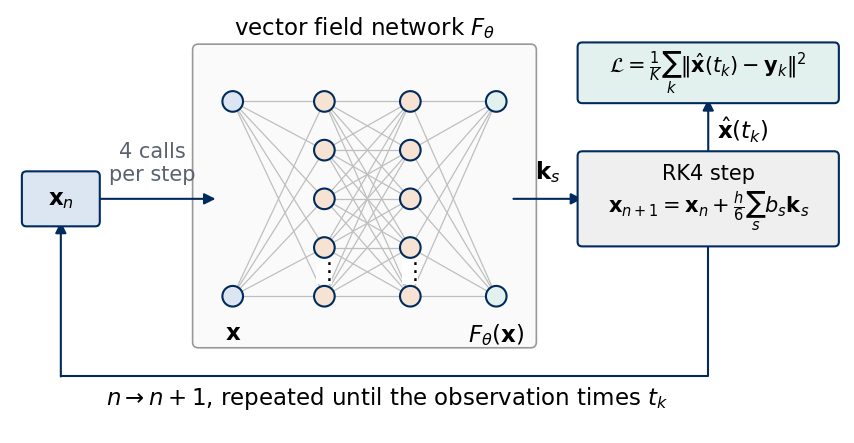

In [4]:
def draw_layers(ax, sizes, labels, xs, ys_span=2.2, node_r=0.11, colors=None, edge_color="0.75"):
    """Nodes-and-edges drawing of a fully connected network, columns at x = xs, labels below the columns."""
    cols = []
    for n, x in zip(sizes, xs):
        ys = np.linspace(ys_span / 2, -ys_span / 2, n) if n > 1 else np.array([0.0])
        cols.append([(x, y) for y in ys])
    for a, b in zip(cols[:-1], cols[1:]):
        for (x0, y0) in a:
            for (x1, y1) in b:
                ax.plot([x0, x1], [y0, y1], color=edge_color, lw=0.6, zorder=1)
    for i, col in enumerate(cols):
        for (x, y) in col:
            ax.add_patch(Circle((x, y), node_r, fc=(colors[i] if colors else "#DCE6F2"), ec=UJNavy, lw=1.0, zorder=3))
    for i, lab in enumerate(labels):
        ax.text(xs[i], -ys_span / 2 - 0.22, lab, ha="center", va="top", linespacing=1.1)
    return cols

def box(ax, x, y, text, w, h, fc, **kw):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.04", fc=fc, ec=UJNavy, lw=1.0, zorder=3))
    ax.text(x, y, text, ha="center", va="center", zorder=4, **kw)

def arrow(ax, p, q, **kw):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=UJNavy, lw=1.0, shrinkA=0, shrinkB=0, **kw), zorder=2)

with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.8)); ax = fig.add_axes([0, 0, 1, 1])
    # the vector-field network F_theta: state in, velocity out
    ax.add_patch(FancyBboxPatch((1.55, -1.25), 2.9, 2.55, boxstyle="round,pad=0.05", fc="#FAFAFA", ec="0.6", lw=0.8, zorder=0))
    cols = draw_layers(ax, [2, 5, 5, 2], [r"$\mathbf{x}$", "", "", r"$F_\theta(\mathbf{x})$"], xs=[1.85, 2.65, 3.4, 4.15],
                       ys_span=1.7, node_r=0.09, colors=["#DCE6F2", "#F6E3D3", "#F6E3D3", "#E3F1EE"])
    for col in cols[1:3]:
        ax.text(col[0][0], 0.5 * (col[-2][1] + col[-1][1]), r"$\vdots$", ha="center", va="center", zorder=4,
                bbox=dict(fc="white", ec="none", pad=0.3))
    ax.text(3.0, 1.38, r"vector field network $F_\theta$", ha="center", va="bottom")
    # solver loop
    box(ax, 0.35, 0.0, r"$\mathbf{x}_n$", 0.6, 0.4, "#DCE6F2")
    box(ax, 6.0, 0.0, "RK4 step\n" + r"$\mathbf{x}_{n+1}=\mathbf{x}_n+\frac{h}{6}\sum_s b_s\mathbf{k}_s$", 2.2, 0.75, "#EFEFEF", fontsize=10)
    arrow(ax, (0.65, 0.0), (1.7, 0.0))
    ax.text(1.15, 0.12, "4 calls\nper step", ha="center", va="bottom", fontsize=10, color=UJGray)
    arrow(ax, (4.3, 0.0), (4.9, 0.0)); ax.text(4.6, 0.12, r"$\mathbf{k}_s$", ha="center", va="bottom")
    # feedback path below the network: the new state is the input of the next step
    ax.plot([6.0, 6.0, 0.35], [-0.38, -1.55, -1.55], color=UJNavy, lw=1.0, zorder=2)
    arrow(ax, (0.35, -1.55), (0.35, -0.2))
    ax.text(3.2, -1.62, r"$n\to n+1$, repeated until the observation times $t_k$", ha="center", va="top")
    box(ax, 6.0, 1.1, r"$\mathcal{L}=\frac{1}{K}\sum_k\|\hat{\mathbf{x}}(t_k)-\mathbf{y}_k\|^2$", 2.2, 0.45, "#E3F1EE", fontsize=10)
    arrow(ax, (6.0, 0.38), (6.0, 0.87)); ax.text(6.08, 0.6, r"$\hat{\mathbf{x}}(t_k)$", ha="left", va="center")
    ax.set_xlim(-0.05, 7.15); ax.set_ylim(-2.0, 1.6); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lab042_node_architecture"); plt.show()

### Two ways to compute the gradient

The first way treats the solver as a program. With a fixed step $h$ the prediction is a composition of RK4 steps, each a composition of network calls, and reverse-mode automatic differentiation (backpropagation) through all of them gives the gradient of the discretised loss up to rounding errors. This approach is called discretise-then-optimise. Backpropagation needs the intermediate values of the forward pass, so its memory grows in proportion to the number of steps.

The second way, optimise-then-discretise, derives an equation for the gradient of the continuous problem and solves it numerically. Consider first a loss $\mathcal L(\mathbf x(T))$ that depends on the final state only. A small change $\delta\theta$ of the parameters changes the trajectory by $\delta\mathbf x(t)$, which obeys the linearised equation
$$\delta\dot{\mathbf x}=J(t)\,\delta\mathbf x+\frac{\partial F_\theta}{\partial\theta}\delta\theta,\qquad J(t)=\frac{\partial F_\theta}{\partial\mathbf x}\Big|_{\mathbf x(t)},\qquad \delta\mathbf x(0)=0 . \tag{8}$$
Let the adjoint state $\mathbf a(t)$, a vector that measures how the loss responds to a small change of the state at time $t$, solve
$$\dot{\mathbf a}(t)=-J(t)^\top\mathbf a(t),\qquad \mathbf a(T)=\frac{\partial\mathcal L}{\partial\mathbf x(T)} . \tag{9}$$
Then
$$\frac{d}{dt}\big(\mathbf a^\top\delta\mathbf x\big)=\mathbf a^\top\frac{\partial F_\theta}{\partial\theta}\delta\theta , \tag{10}$$
since the two terms with $J$ cancel. Integrating from $0$ to $T$ and using $\delta\mathbf x(0)=0$ gives
$$\delta\mathcal L=\mathbf a(T)^\top\delta\mathbf x(T)=\int_0^T\mathbf a^\top\frac{\partial F_\theta}{\partial\theta}dt\,\delta\theta , \tag{11}$$
hence
$$\frac{d\mathcal L}{d\theta}=\int_0^T\mathbf a(t)^\top\frac{\partial F_\theta}{\partial\theta}\Big|_{\mathbf x(t)}dt . \tag{12}$$
The adjoint is integrated backwards from $t=T$ to $t=0$. With observations at several times the loss is a sum of terms, and by linearity $\mathbf a$ receives the jump $\partial\mathcal L/\partial\mathbf x(t_k)$ whenever the backward integration passes an observation time. The state $\mathbf x(t)$ needed in $J(t)$ is recomputed by integrating the Neural ODE backwards together with $\mathbf a$ and the running integral $\mathbf g(t)$ of the gradient, so the augmented system
$$\frac{d}{dt}\begin{pmatrix}\mathbf x\\ \mathbf a\\ \mathbf g\end{pmatrix}=\begin{pmatrix}F_\theta(\mathbf x)\\ -J^\top\mathbf a\\ -\big(\partial F_\theta/\partial\theta\big)^\top\mathbf a\end{pmatrix},\qquad \mathbf g(T)=0,\qquad \mathbf g(0)=\frac{d\mathcal L}{d\theta}, \tag{13}$$
is solved from $T$ to $0$. The products $J^\top\mathbf a$ and $(\partial F_\theta/\partial\theta)^\top\mathbf a$ are vector-Jacobian products, which `jax.vjp` evaluates at the cost of about one backward pass through the network, and the memory no longer depends on the number of steps. The same equations are the costate equations of Pontryagin's optimal control theory. Their use for Neural ODEs, with the backward recomputation of $\mathbf x(t)$, is due to Chen *et al.*, and Kidger reviews the method and its variants.

The adjoint gradient is the gradient of the continuous loss computed with a numerical error, and it differs from the backpropagation gradient of the discretised loss by an amount that vanishes with the step size. The backward reconstruction of $\mathbf x(t)$ is also a source of error, since a contracting forward flow expands when integrated backwards [A. Gholami, K. Keutzer, G. Biros, [arXiv:1902.10298](https://arxiv.org/abs/1902.10298)].

In [5]:
GAMMA_P = 0.2                                       # damping of the pendulum used in this section and in Section 3
f_dp = lambda y: jnp.array([y[1], -jnp.sin(y[0]) - GAMMA_P * y[1]])
DT_OBS, N_OBS = 0.1, 50                             # observations every 0.1 time units, 50 of them
x0_g = jnp.array([1.0, 0.0])
Y_g = rk4_path(f_dp, x0_g, 0.01, N_OBS, sub=10)     # observed states y_k = x(t_k), t_k = 0.1 k, k = 1..50
p_g = init_mlp(jax.random.key(0), [2, 32, 32, 2])   # an untrained vector-field network
F = lambda p, x: mlp(p, x)

def loss_direct(p, sub):
    # discretise-then-optimise: RK4 with `sub` steps per observation interval; jax.grad differentiates through all steps
    xs = rk4_path(lambda x: F(p, x), x0_g, DT_OBS / sub, N_OBS, sub)
    return jnp.mean(jnp.sum((xs - Y_g)**2, 1))

def grad_adjoint(p, sub):
    # optimise-then-discretise: forward solve, then the adjoint system integrated backwards with the same RK4 step
    h = DT_OBS / sub
    xs = rk4_path(lambda x: F(p, x), x0_g, h, N_OBS, sub)
    dLdx = 2 * (xs - Y_g) / N_OBS                     # dL/dx(t_k), the jumps of the adjoint at the observation times
    flat, unravel = ravel_pytree(p)
    def aug(s):
        # augmented system for (x, a, g): dx/dt = F, da/dt = -(dF/dx)^T a, dg/dt = -(dF/dtheta)^T a
        x, a, g = s
        fx, vjp = jax.vjp(lambda x, q: F(unravel(q), x), x, flat)
        ax, aq = vjp(a)
        return (fx, -ax, -aq)
    def rk4_tree(s, h):
        add = lambda s, k, c: jax.tree.map(lambda u, v: u + c * v, s, k)
        k1 = aug(s); k2 = aug(add(s, k1, h / 2)); k3 = aug(add(s, k2, h / 2)); k4 = aug(add(s, k3, h))
        return jax.tree.map(lambda y, a, b, c, d: y + h / 6 * (a + 2 * b + 2 * c + d), s, k1, k2, k3, k4)
    def interval(s, k):
        # integrate backwards from t_{k+1} to t_k, then add the jump dL/dx(t_k) (no observation at t_0)
        s = jax.lax.fori_loop(0, sub, lambda i, s: rk4_tree(s, -h), s)
        a = s[1] + jnp.where(k > 0, 1.0, 0.0) * dLdx[jnp.maximum(k - 1, 0)]
        return (s[0], a, s[2]), None
    s0 = (xs[-1], dLdx[-1], jnp.zeros_like(flat))
    s, _ = jax.lax.scan(interval, s0, jnp.arange(N_OBS - 1, -1, -1))
    return unravel(s[2])

T_OBS = DT_OBS * np.arange(1, N_OBS + 1)               # observation times as a numpy array (static for diffrax)
def loss_diffrax(p, sub, adjoint=diffrax.RecursiveCheckpointAdjoint()):
    # the same loss with diffrax: our RK4 tableau, constant step, states saved at the observation times;
    # the default RecursiveCheckpointAdjoint backpropagates through the solver steps with checkpointing
    sol = diffrax.diffeqsolve(diffrax.ODETerm(lambda t, y, args: F(args, y)), RK4(), 0.0, float(T_OBS[-1]), DT_OBS / sub,
                              x0_g, args=p, saveat=diffrax.SaveAt(ts=jnp.asarray(T_OBS)), stepsize_controller=diffrax.ConstantStepSize(),
                              adjoint=adjoint)
    return jnp.mean(jnp.sum((sol.ys - Y_g)**2, 1))

We test both methods on a damped pendulum,
$$\dot\theta=\omega,\qquad \dot\omega=-\sin\theta-0.2\,\omega, \tag{14}$$
observed at 50 times spaced by $0.1$ from $(\theta,\omega)=(1,0)$, with an untrained network $F_\theta$ of two hidden layers of 32 tanh units. Four gradients of the same loss are computed. Backpropagation through our RK4 uses `jax.grad`, and our adjoint solver integrates the augmented system backwards with RK4 and the same step. diffrax computes the gradient with its default method, backpropagation through the solver steps with recursive checkpointing (`RecursiveCheckpointAdjoint`), which stores the state only at a limited number of checkpoints and recomputes the steps between them, and with the continuous adjoint (`BacksolveAdjoint`). diffrax integrates with our RK4 tableau, so all four use the same discretisation. The step is $h=0.1/n_{\rm sub}$ with $n_{\rm sub}=1,4,16,64$ steps per observation interval. The working memory is the size of the temporary buffers that XLA, the compiler used by JAX, allocates for the compiled gradient function, and the time is the median over repeated calls. Wall times depend on hardware and concurrent system load; the quoted values describe this recorded run.

In [6]:
rel = lambda a, b: float(jnp.linalg.norm(ravel_pytree(a)[0] - ravel_pytree(b)[0]) / jnp.linalg.norm(ravel_pytree(b)[0]))
GRADS = {"backprop through RK4": jax.jit(jax.grad(loss_direct), static_argnums=1),
         "own adjoint": jax.jit(grad_adjoint, static_argnums=1),
         "diffrax checkpointed": jax.jit(jax.grad(loss_diffrax), static_argnums=1),
         "diffrax backsolve": jax.jit(jax.grad(lambda p, s: loss_diffrax(p, s, diffrax.BacksolveAdjoint())), static_argnums=1)}
rows_adj = []
for sub in (1, 4, 16, 64):
    g = {k: fn(p_g, sub) for k, fn in GRADS.items()}
    row = dict(sub=sub, n_steps=N_OBS * sub,
               adj_vs_bp=rel(g["own adjoint"], g["backprop through RK4"]),
               dfx_vs_bp=rel(g["diffrax checkpointed"], g["backprop through RK4"]),
               dfxback_vs_adj=rel(g["diffrax backsolve"], g["own adjoint"]))
    for k, fn in GRADS.items():
        row["mem " + k] = fn.lower(p_g, sub).compile().memory_analysis().temp_size_in_bytes
        row["time " + k] = timed(fn, p_g, sub)
    rows_adj.append(row)
    print(f"{N_OBS * sub:5d} RK4 steps: |own adjoint - backprop|/|backprop| = {row['adj_vs_bp']:.1e},"
          f" diffrax checkpointed vs backprop {row['dfx_vs_bp']:.1e}, diffrax backsolve vs own adjoint {row['dfxback_vs_adj']:.1e}")
print()
print(f"{'gradient':22s}" + "".join(f"{str(r['n_steps']) + ' steps':>22s}" for r in rows_adj))
for k in GRADS:
    print(f"{k:22s}" + "".join(f"{r['mem ' + k] / 1e3:9.0f} kB {r['time ' + k] * 1e3:7.1f} ms" for r in rows_adj))
nums["adjoint"] = rows_adj

   50 RK4 steps: |own adjoint - backprop|/|backprop| = 4.2e-08, diffrax checkpointed vs backprop 4.1e-16, diffrax backsolve vs own adjoint 1.0e-09
  200 RK4 steps: |own adjoint - backprop|/|backprop| = 1.6e-10, diffrax checkpointed vs backprop 1.2e-15, diffrax backsolve vs own adjoint 1.7e-10
  800 RK4 steps: |own adjoint - backprop|/|backprop| = 6.4e-13, diffrax checkpointed vs backprop 1.2e-15, diffrax backsolve vs own adjoint 1.7e-13
 3200 RK4 steps: |own adjoint - backprop|/|backprop| = 3.2e-15, diffrax checkpointed vs backprop 2.5e-15, diffrax backsolve vs own adjoint 1.7e-15

gradient                            50 steps             200 steps             800 steps            3200 steps
backprop through RK4        212 kB     0.8 ms      863 kB     3.3 ms     3409 kB    10.3 ms    13592 kB    35.8 ms
own adjoint                  25 kB     1.0 ms       26 kB     3.4 ms       26 kB    13.6 ms       26 kB    54.1 ms
diffrax checkpointed         29 kB     3.6 ms       29 kB    15.3 ms  

With one RK4 step per observation interval, 50 steps in total, our adjoint gradient differs from backpropagation by $4.2\times10^{-8}$ relative to its norm. Every division of the step by four reduces the difference by a factor of about $256=4^4$, down to $3.2\times10^{-15}$ at 3200 steps, so the two methods converge to the same gradient at the rate of the fourth-order solver. The checkpointed backpropagation of diffrax agrees with ours to at most $2.5\times10^{-15}$, and the diffrax `BacksolveAdjoint` agrees with our adjoint to $1.0\times10^{-9}$ at 50 steps and $1.7\times10^{-15}$ at 3200 steps. The left panel shows the working memory of the four gradient computations against the number of RK4 steps, the right panel the relative difference $\|\nabla_{\rm adj}-\nabla_{\rm bp}\|/\|\nabla_{\rm bp}\|$ between our adjoint gradient and backpropagation, with a dotted line of slope $-4$.

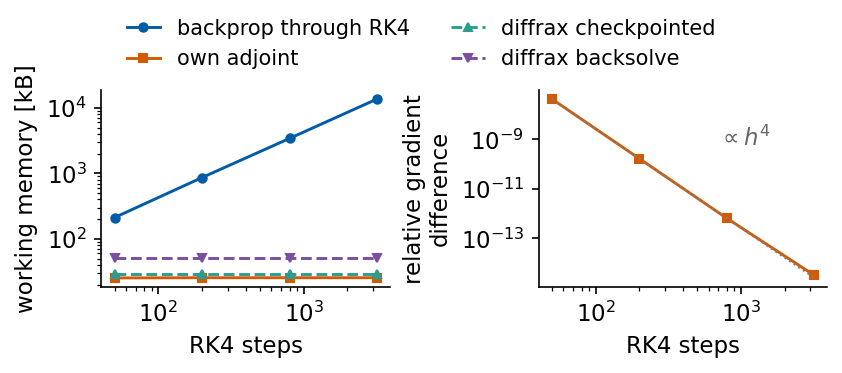

In [7]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained")
    ns = [r["n_steps"] for r in rows_adj]
    mk = {"backprop through RK4": ("o-", UJBlue), "own adjoint": ("s-", DSOrange),
          "diffrax checkpointed": ("^--", "#2A9D8F"), "diffrax backsolve": ("v--", "#7B4FA0")}
    for k, (m_, c) in mk.items():
        axs[0].loglog(ns, [r["mem " + k] / 1e3 for r in rows_adj], m_, color=c, ms=4, label=k)
    axs[0].set_xlabel("RK4 steps"); axs[0].set_ylabel("working memory [kB]")
    axs[1].loglog(ns, [r["adj_vs_bp"] for r in rows_adj], "s-", color=DSOrange, ms=4)
    axs[1].loglog(ns, rows_adj[0]["adj_vs_bp"] * (np.array(ns) / ns[0])**-4.0, ":", color="0.5", lw=1.0)   # slope of h^4
    axs[1].text(0.62, 0.72, r"$\propto h^4$", color="0.4", transform=axs[1].transAxes)
    axs[1].set_xlabel("RK4 steps"); axs[1].set_ylabel("relative gradient\ndifference")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside upper center", ncol=2, fontsize=10, handlelength=1.6)
    save(fig, "fig_lab042_adjoint_memory"); plt.show()

Backpropagation through RK4 needs 212 kB of working memory at 50 steps and 13592 kB at 3200 steps, in proportion to the number of steps, while our adjoint needs 25 to 26 kB and the diffrax `BacksolveAdjoint` 51 kB at every step count. The price of the constant memory is time. In this recorded run, at 3200 steps our adjoint takes 54 ms against 36 ms for backpropagation, since it integrates the state a second time, backwards, together with the adjoint. The checkpointed backpropagation of diffrax also needs a constant 29 kB, since it keeps only the checkpoints, and pays for the recomputation of the steps between them with the longest time of the four, 255 ms at 3200 steps. For the small networks and short segments used here the memory of backpropagation is affordable, and we train all models of the following sections by backpropagation through our RK4. The adjoint method becomes necessary when long integrations or large states make the stored forward pass too large.

<hr/>
## 3. Damped pendulum

The damped pendulum
$$\dot\theta=\omega,\qquad \dot\omega=-\omega_p^2\sin\theta-\gamma\,\omega, \tag{15}$$
with $\omega_p=1$ and $\gamma=0.2$, describes the angle $\theta$ and the angular velocity $\omega$ of a pendulum whose damping term $-\gamma\omega$, a friction that opposes the motion, turns the energy of the swing into heat. The energy changes at the rate
$$\frac{d}{dt}\Big(\tfrac12\omega^2-\omega_p^2\cos\theta\Big)=-\gamma\omega^2 , \tag{16}$$
so the swing decays. The pendulum has two kinds of fixed points, states at which the vector field vanishes and the pendulum stays at rest. Their character follows from the eigenvalues of the Jacobian, the matrix of first derivatives of the vector field, at the fixed point. At the hanging position $(0,0)$ the Jacobian
$$\frac{\partial(\dot\theta,\dot\omega)}{\partial(\theta,\omega)}\Big|_{(0,0)}=\begin{pmatrix}0&1\\-\omega_p^2&-\gamma\end{pmatrix} \tag{17}$$
has the complex eigenvalues $-\gamma/2\pm i\sqrt{\omega_p^2-\gamma^2/4}$ with negative real part, so nearby trajectories circle the point while approaching it, which makes it a stable spiral. The upright position $(\pi,0)$ is a saddle, a fixed point that attracts states along one direction and repels them along another, with one positive and one negative eigenvalue, $-\gamma/2\pm\sqrt{\omega_p^2+\gamma^2/4}$. Every trajectory that starts inside the separatrix of the undamped pendulum, the curve through the upright positions that divides swinging from rotating motion, spirals into the hanging position.

We measure both components of the state, $(\theta,\omega)$, every $\Delta t=0.1$ on eight trajectories over the training window $0\le t\le10$, with independent Gaussian noise of standard deviation $0.01$ on every component. The initial states are drawn uniformly in $|\theta|<2.6$, $|\omega|<1.8$ and kept when their energy $\tfrac12\omega^2-\cos\theta$ is below $0.9$, so that every trajectory oscillates. Three further initial states drawn in the same way are the test cases.

In [8]:
N_TRAJ, T_TRAIN, SIG_P = 8, 10.0, 0.01            # trajectories, training window, noise of the measured state
N_S = int(round(T_TRAIN / DT_OBS))                  # 100 intervals per trajectory
rng = np.random.default_rng(1)
def energy_p(y):
    return 0.5 * y[..., 1]**2 - np.cos(y[..., 0])
# initial states inside the separatrix (energy below 0.9), drawn uniformly in the box |theta| < 2.6, |omega| < 1.8
IC = []
while len(IC) < N_TRAJ + 3:
    y = rng.uniform([-2.6, -1.8], [2.6, 1.8])
    if energy_p(y) < 0.9:
        IC.append(y)
IC = np.array(IC); IC_TRAIN, IC_TEST = IC[:N_TRAJ], IC[N_TRAJ:]
def true_path(y0, n, h=0.01, sub=10):
    return np.concatenate([np.asarray(y0)[None], np.asarray(rk4_path(f_dp, jnp.asarray(y0), h, n, sub))])
X_true = np.stack([true_path(y0, N_S) for y0 in IC_TRAIN])                 # (8, 101, 2), t = 0, 0.1, ..., 10
Y_p = X_true + SIG_P * rng.normal(size=X_true.shape)                         # measured states
print(f"{N_TRAJ} training trajectories of {N_S + 1} states each, noise sigma = {SIG_P}; energies of the initial states:",
      np.round(energy_p(IC_TRAIN), 2))
print("test initial states:", np.round(IC_TEST, 2).tolist())

8 training trajectories of 101 states each, noise sigma = 0.01; energies of the initial states: [ 0.32 -0.52  0.19  0.48 -0.24 -0.09 -0.51  0.39]
test initial states: [[-1.54, -0.86], [1.3, -0.79], [-0.08, 1.73]]


The figure shows the measured states of the eight training trajectories in the phase plane (blue dots), their initial states (dark circles) and the three test initial states (orange stars). The data cover a band of spirals around the origin, and the region near the saddles at $\theta=\pm\pi$ contains no data.

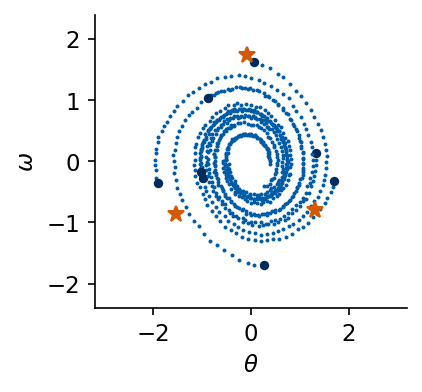

In [9]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(2.7, 2.5), layout="constrained")
    for i in range(N_TRAJ):
        ax.plot(Y_p[i, :, 0], Y_p[i, :, 1], ".", ms=1.8, color=UJBlue)
        ax.plot(*IC_TRAIN[i], "o", ms=3.5, color=UJNavy)
    for y0 in IC_TEST:
        ax.plot(*y0, "*", ms=8, color=DSOrange)
    ax.set_xlabel(r"$\theta$"); ax.set_ylabel(r"$\omega$"); ax.set_xlim(-3.2, 3.2); ax.set_ylim(-2.4, 2.4)
    save(fig, "fig_lab042_pendulum_data"); plt.show()

### Training

The vector field is an MLP with two inputs, two hidden layers of 64 tanh units and two outputs. We train it by multiple shooting [P. Kidger, [arXiv:2202.02435](https://arxiv.org/abs/2202.02435)]. A minibatch consists of 64 segments, each starting at a measured state $\mathbf y_j$ of a random trajectory and covering the next 10 intervals, one time unit. From every starting state the Neural ODE is integrated with RK4 and two steps per interval, and the loss is the mean squared difference between the 10 predicted and measured states. Short segments keep the predicted and measured trajectories close at every step, so the loss landscape stays smooth, and the starting states bring the noise of a single measurement into the segment. We run 3000 Adam steps with gradient clipping at norm 1 and a learning rate decreasing from $3\times10^{-3}$ along a cosine.

For B segments of S steps in a d-dimensional state, the implemented loss is $\mathcal L=(BSd)^{-1}\sum_{b=1}^{B}\sum_{j=1}^{S}\|\hat{\mathbf x}_{b,j}-\mathbf y_{b,j}\|^2$. Here d=2.

In [10]:
SEG, SUB_P, BATCH = 10, 2, 64                        # segment length (intervals), RK4 steps per interval, minibatch
WIDTH_P = 64
def node_segments(p, x0, n, sub=SUB_P):
    # Neural ODE forecast of n intervals of length DT_OBS from the measured state x0
    return rk4_path(lambda x: mlp(p, x), x0, DT_OBS / sub, n, sub)

Yp_j = jnp.asarray(Y_p)
def sampler_p(key):
    k1, k2 = jax.random.split(key)
    return jax.random.randint(k1, (BATCH,), 0, N_TRAJ), jax.random.randint(k2, (BATCH,), 0, N_S - SEG + 1)
def loss_p(p, batch):
    # multiple shooting: each segment starts at a measured state and is compared with the next SEG measured states
    i, j = batch
    pred = jax.vmap(lambda x0: node_segments(p, x0, SEG))(Yp_j[i, j])
    tgt = jax.vmap(lambda ii, jj: jax.lax.dynamic_slice_in_dim(Yp_j[ii], jj + 1, SEG))(i, j)
    return jnp.mean((pred - tgt)**2)

p_pend, h_pend = train_adam(loss_p, init_mlp(jax.random.key(0), [2, WIDTH_P, WIDTH_P, 2]), sampler_p, steps=3000, lr=3e-3)
print(f"Neural ODE with {n_params(p_pend)} parameters trained in {h_pend['time']:.0f} s; final minibatch loss {h_pend['final']:.2e}"
      f" (noise variance {SIG_P**2:.0e})")
nums["pend_node"] = dict(n_params=n_params(p_pend), time=h_pend["time"], loss=h_pend["final"])

Neural ODE with 4482 parameters trained in 52 s; final minibatch loss 2.08e-04 (noise variance 1e-04)


The network has 4482 parameters and trains in about 52 s in this recorded run. The final minibatch loss, $2.1\times10^{-4}$, is close to $2\sigma^2=2\times10^{-4}$, the sum of the noise variances in the starting state and in the target. The starting-state noise is transformed by the flow over the segment, so $2\sigma^2$ is an estimate. The figure compares the true vector field $\mathbf F(\theta,\omega)$ (left) and the learned field $F_\theta(\theta,\omega)$ (middle) as streamlines, and the right panel shows the relative error $\|F_\theta-\mathbf F\|/\|\mathbf F\|$ on a logarithmic colour scale, with the measured states as white dots. The denominator is bounded from below by $0.01$ to avoid the division by zero at the fixed points.

median relative error of the learned field: 0.012 within 0.2 of the data, 0.231 farther away


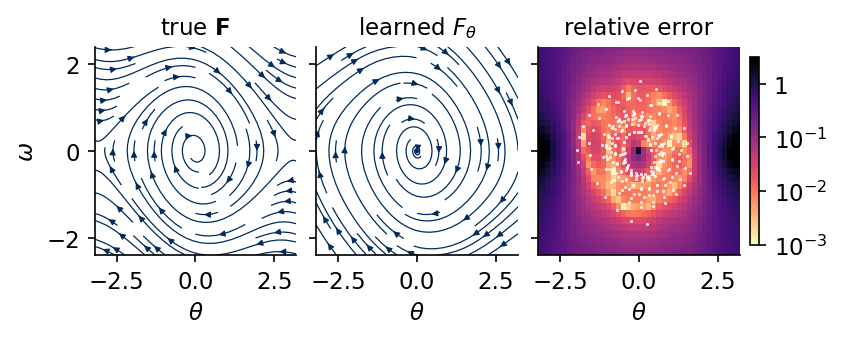

In [11]:
th_g, om_g = np.meshgrid(np.linspace(-3.2, 3.2, 41), np.linspace(-2.4, 2.4, 31))
G = jnp.stack([th_g.ravel(), om_g.ravel()], 1)
F_true = np.asarray(jax.vmap(f_dp)(G)); F_lrn = np.asarray(jax.vmap(lambda x: mlp(p_pend, x))(G))
rel_err = (np.linalg.norm(F_lrn - F_true, axis=1) / np.maximum(np.linalg.norm(F_true, axis=1), 1e-2)).reshape(th_g.shape)
# distance of each grid point to the nearest training state, to separate the visited from the unvisited region
pts = Y_p.reshape(-1, 2)
dist = np.min(np.linalg.norm(G[:, None, :] - pts[None, :, :], axis=2), axis=1).reshape(th_g.shape)
near = dist < 0.2
print(f"median relative error of the learned field: {np.median(rel_err[near]):.3f} within 0.2 of the data,"
      f" {np.median(rel_err[~near]):.3f} farther away")
nums["pend_field"] = dict(err_near=float(np.median(rel_err[near])), err_far=float(np.median(rel_err[~near])))
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.15), layout="constrained", sharey=True)
    for ax, Fv, ttl in ((axs[0], F_true, r"true $\mathbf{F}$"), (axs[1], F_lrn, r"learned $F_\theta$")):
        ax.streamplot(th_g, om_g, Fv[:, 0].reshape(th_g.shape), Fv[:, 1].reshape(th_g.shape), density=0.7,
                      color=UJNavy, linewidth=0.6, arrowsize=0.6)
        ax.set_title(ttl); ax.set_xlabel(r"$\theta$")
    im = axs[2].pcolormesh(th_g, om_g, np.log10(rel_err), cmap="magma_r", vmin=-3, vmax=0.5, shading="auto")
    axs[2].plot(pts[::3, 0], pts[::3, 1], ".", ms=0.8, color="w")
    axs[2].set_title("relative error"); axs[2].set_xlabel(r"$\theta$")
    cb = fig.colorbar(im, ax=axs[2], shrink=0.9, ticks=[-3, -2, -1, 0]); cb.ax.set_yticklabels(["$10^{-3}$", "$10^{-2}$", "$10^{-1}$", "1"])
    axs[0].set_ylabel(r"$\omega$")
    for ax in axs: ax.set_xlim(-3.2, 3.2); ax.set_ylim(-2.4, 2.4)
    save(fig, "fig_lab042_pendulum_field"); plt.show()

Within a distance 0.2 of the measured states the median relative error of the learned field is 0.012, and farther away it is 0.23. The network learns the vector field in the band of state space that the trajectories cross and continues it smoothly elsewhere. Near the saddles at $\theta=\pm\pi$, where there are no data, the learned streamlines differ visibly from the true ones, so the learned model is reliable only in the region covered by the data.

We integrate the learned field from the three test initial states up to $t=30$, three times the training window, with our RK4 and with the adaptive Tsit5 solver of diffrax at tolerance $10^{-9}$. Each panel of the forecast figure shows the true angle $\theta(t)$ and the Neural ODE forecast, with the training window shaded.

initial state [-1.54 -0.86]: max |theta error| for t <= 10 6.7e-02, for 10 < t <= 30 7.6e-02; own RK4 vs diffrax Tsit5 2.7e-07
initial state [ 1.3  -0.79]: max |theta error| for t <= 10 8.7e-03, for 10 < t <= 30 8.2e-02; own RK4 vs diffrax Tsit5 2.4e-07
initial state [-0.08  1.73]: max |theta error| for t <= 10 1.6e-02, for 10 < t <= 30 8.1e-02; own RK4 vs diffrax Tsit5 2.6e-07


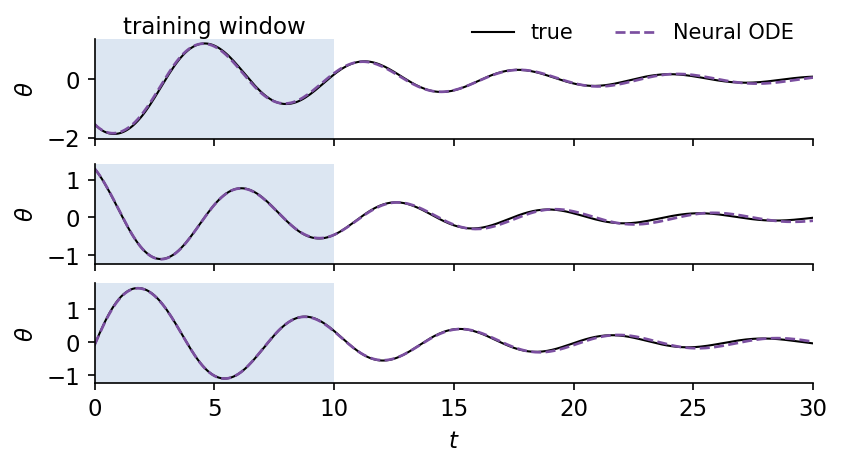

In [12]:
T_FC = 30.0; n_fc = int(round(T_FC / DT_OBS))
t_fc = DT_OBS * np.arange(n_fc + 1)
fc_rows = []
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(len(IC_TEST), 1, figsize=(5.5, 3.0), layout="constrained", sharex=True)
    for ax, y0 in zip(axs, IC_TEST):
        tru = true_path(y0, n_fc)
        own = np.concatenate([y0[None], np.asarray(node_segments(p_pend, jnp.asarray(y0), n_fc))])
        sol = diffrax.diffeqsolve(diffrax.ODETerm(lambda t, y, args: mlp(p_pend, y)), diffrax.Tsit5(), 0.0, T_FC, 0.05,
                                  jnp.asarray(y0), saveat=diffrax.SaveAt(ts=jnp.asarray(t_fc)),
                                  stepsize_controller=diffrax.PIDController(rtol=1e-9, atol=1e-9), max_steps=100000)
        lib = np.asarray(sol.ys)
        e_in = np.abs(own[t_fc <= T_TRAIN, 0] - tru[t_fc <= T_TRAIN, 0]).max()
        e_out = np.abs(own[t_fc > T_TRAIN, 0] - tru[t_fc > T_TRAIN, 0]).max()
        fc_rows.append(dict(ic=y0.tolist(), err_in=float(e_in), err_out=float(e_out), own_vs_dfx=float(np.abs(own - lib).max())))
        ax.axvspan(0, T_TRAIN, color="#DCE6F2", lw=0, zorder=0)
        ax.plot(t_fc, tru[:, 0], color="k", lw=1.0, label="true")
        ax.plot(t_fc, own[:, 0], "--", color=STYLE["Neural ODE"]["color"], lw=1.3, label="Neural ODE")
        ax.set_ylabel(r"$\theta$"); ax.set_xlim(0, T_FC)
    axs[0].text(T_TRAIN / 2, axs[0].get_ylim()[1], "training window", ha="center", va="bottom")
    axs[-1].set_xlabel("$t$")
    axs[0].legend(loc="upper right", ncol=2, fontsize=10, bbox_to_anchor=(1.0, 1.35))
    save(fig, "fig_lab042_pendulum_forecast"); plt.show()
for r in fc_rows:
    print(f"initial state {np.round(r['ic'], 2)}: max |theta error| for t <= 10 {r['err_in']:.1e}, for 10 < t <= 30 {r['err_out']:.1e};"
          f" own RK4 vs diffrax Tsit5 {r['own_vs_dfx']:.1e}")
nums["pend_forecast"] = fc_rows

Inside the training window the largest deviation of $\theta$ on the three test trajectories is between $8.7\times10^{-3}$ and $6.7\times10^{-2}$, and for $10<t\le30$ it stays below $8.2\times10^{-2}$ while the oscillation decays. Our RK4 and the Tsit5 integration of the learned field agree to $2.7\times10^{-7}$, so the forecast error comes from the learned field and the solver contributes nothing visible. The test trajectories start inside the region covered by the training data, and beyond $t=10$ they spiral into the centre, where the data are densest, which explains why the forecast stays accurate three times beyond the training window.

<hr/>
## 4. Lorenz-63

The Lorenz-63 model is a three-mode truncation of the equations of thermal convection in a fluid layer heated from below [E. N. Lorenz, J. Atmos. Sci. **20**, 130 (1963), [doi:10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2](https://doi.org/10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2)],
$$\dot x=\sigma(y-x),\qquad \dot y=x(\rho-z)-y,\qquad \dot z=xy-\beta z . \tag{18}$$
The variable $x$ measures the rate of convective circulation, $y$ the horizontal and $z$ the vertical temperature variation, $\sigma$ is the Prandtl number, the ratio of the viscosity of the fluid to its thermal diffusivity, $\rho$ the normalised Rayleigh number, which measures the strength of the heating relative to the damping by viscosity and heat conduction, and $\beta$ a geometric factor. With the standard values $\sigma=10$, $\rho=28$, $\beta=8/3$ the flow has three unstable fixed points, the origin and the two states of steady convection $C_\pm=\big(\pm\sqrt{\beta(\rho-1)},\pm\sqrt{\beta(\rho-1)},\rho-1\big)$, and the trajectories settle on a chaotic attractor that winds around $C_+$ and $C_-$, a bounded set of states on which the motion never repeats and nearby trajectories separate exponentially. The divergence of the flow, the sum $\partial\dot x/\partial x+\partial\dot y/\partial y+\partial\dot z/\partial z$ that gives the relative rate at which a small volume of states grows or shrinks, is constant,
$$\nabla\cdot\mathbf F=-(\sigma+1+\beta), \tag{19}$$
so volumes in state space contract at this rate.

We generate the data with RK4 at step $h=0.01$ from $(1,1,1)$, keep every second state, which gives the sampling interval $\Delta t=0.02$, discard the first 2500 samples (50 time units) and keep 8000 samples of the full state $(x,y,z)$. We also evaluate the fixed points and the eigenvalues of the Jacobian there.

In [13]:
SIGMA_L, RHO_L, BETA_L = 10.0, 28.0, 8.0 / 3.0
def lorenz_rhs(u):
    x, y, z = u
    return jnp.array([SIGMA_L * (y - x), x * (RHO_L - z) - y, x * y - BETA_L * z])
H_L, SUB_L = 0.01, 2                                # RK4 step and steps per sample, sampling interval dt = 0.02
DT_L = H_L * SUB_L
N_L, N_DISCARD = 8000, 2500
U_all = np.asarray(rk4_path(lorenz_rhs, jnp.array([1.0, 1.0, 1.0]), H_L, N_L + N_DISCARD, SUB_L))
U_L = U_all[N_DISCARD:]                             # (8000, 3), the first 2500 samples (50 time units) are discarded
N_FIT, N_VAL = 4000, 1000                           # fit 0..3999, validation 4000..4999, test 5000..7999
MU_L, SD_L = U_L[:N_FIT].mean(0), U_L[:N_FIT].std(0)
Z_L = (U_L - MU_L) / SD_L                           # every model works with the standardised state z
print(f"{N_L} samples, dt = {DT_L}; fit mean {np.round(MU_L, 2)}, fit std {np.round(SD_L, 2)}")
# fixed points of the Lorenz flow and the eigenvalues of the Jacobian there
q = np.sqrt(BETA_L * (RHO_L - 1))
FP_TRUE = np.array([[0.0, 0.0, 0.0], [q, q, RHO_L - 1], [-q, -q, RHO_L - 1]])
for u in FP_TRUE:
    ev = np.linalg.eigvals(np.asarray(jax.jacfwd(lorenz_rhs)(jnp.asarray(u))))
    print(f"fixed point {np.round(u, 3)}: eigenvalues {np.round(np.sort_complex(ev), 3)}")

8000 samples, dt = 0.02; fit mean [-0.49 -0.48 23.49], fit std [7.9  9.01 8.66]
fixed point [0. 0. 0.]: eigenvalues [-22.828+0.j  -2.667+0.j  11.828+0.j]
fixed point [ 8.485  8.485 27.   ]: eigenvalues [-13.855 +0.j      0.094-10.195j   0.094+10.195j]
fixed point [-8.485 -8.485 27.   ]: eigenvalues [-13.855 +0.j      0.094-10.195j   0.094+10.195j]


At the origin the Jacobian has the eigenvalues $-22.83$, $-2.67$ and $11.83$, so the conducting state is a saddle with one unstable direction. At $C_\pm$ it has the real eigenvalue $-13.85$ and the complex pair $0.094\pm10.195\,i$, whose small positive real part makes the two convection states weakly unstable spirals. The trajectory circles around one of them with growing amplitude until it is thrown to the other.

### Lyapunov time

Two nearby states on a chaotic attractor separate on average as $e^{\lambda_1t}$, where $\lambda_1$ is the largest Lyapunov exponent. A small initial error of a perfect model therefore grows by a factor $e$ in one Lyapunov time $1/\lambda_1$, and forecasts are compared on the time axis $\lambda_1t$. We compute $\lambda_1$ for the RK4 map with $h=0.01$ by the method of Benettin *et al.* [G. Benettin, L. Galgani, A. Giorgilli, J.-M. Strelcyn, Meccanica **15**, 9 (1980), [doi:10.1007/BF02128236](https://doi.org/10.1007/BF02128236)]. A tangent vector $\mathbf v$, a small perturbation of the state, is propagated with the derivative of the map, $\mathbf v\mapsto D\boldsymbol\Phi_h(\mathbf u)\mathbf v$, which `jax.jvp` evaluates together with the step itself. After every step the vector is normalised, and the average of the logarithms of the norms divided by the step is $\lambda_1$. Ten segments of 100 time units give the standard error.

In [14]:
def lyap_max(step, u0, n_steps, dt, n_seg=10, n_transient=1000):
    """Largest Lyapunov exponent of the map u -> step(u): one tangent vector, propagated with jax.jvp and
    renormalised after every step; returns the mean and the standard error over n_seg segments."""
    u = jax.lax.fori_loop(0, n_transient, lambda i, u: step(u), u0)
    def one(carry, _):
        u, v = carry
        u, v = jax.jvp(step, (u,), (v,))
        nv = jnp.linalg.norm(v)
        return (u, v / nv), jnp.log(nv)
    v0 = jnp.ones_like(u0) / jnp.sqrt(u0.size)
    (_, _), logs = jax.lax.scan(one, (u, v0), None, length=n_steps)
    seg = logs.reshape(n_seg, -1).sum(1) / (n_steps // n_seg * dt)
    return float(seg.mean()), float(seg.std(ddof=1) / np.sqrt(n_seg))

t0 = time.time()
LAM_TRUE, LAM_TRUE_ERR = lyap_max(jax.jit(lambda u: rk4_step(lorenz_rhs, u, H_L)), jnp.asarray(U_L[0]), 100000, H_L)
T_LYAP = 1.0 / LAM_TRUE
print(f"lambda_1 of Lorenz-63 = {LAM_TRUE:.3f} +- {LAM_TRUE_ERR:.3f} per time unit (1000 time units, {time.time() - t0:.0f} s);"
      f" Lyapunov time 1/lambda_1 = {T_LYAP:.3f} = {T_LYAP / DT_L:.1f} samples")
nums["lyap_true"] = dict(lam=LAM_TRUE, err=LAM_TRUE_ERR, t_lyap=T_LYAP)

lambda_1 of Lorenz-63 = 0.906 +- 0.007 per time unit (1000 time units, 1 s); Lyapunov time 1/lambda_1 = 1.104 = 55.2 samples


We find $\lambda_1=0.906\pm0.007$ per time unit, which gives the Lyapunov time $1/\lambda_1=1.104$ time units or 55.2 samples.

### Forecasting protocol

The 8000 samples are split in time order. The first 4000 form the fitting block, the next 1000 the validation block and the last 3000 the test block. Every model is fitted on the fitting block only. Its settings are chosen by the score on the validation block, and the chosen model is scored once on the test block. All models work with the standardised state $\mathbf z=(\mathbf u-\boldsymbol\mu)/\mathbf s$, where $\boldsymbol\mu$ and $\mathbf s$ are the mean and the standard deviation of each component over the fitting block.

From every origin $k$, taken every 5 samples in the validation block and every 10 samples in the test block, each model makes a free-run forecast of 500 samples (10 time units). The model receives the true state at the origin, and from then on every forecast is fed back as the next input. The first score, the forecast capacity at lead $\tau$, is the squared Pearson correlation coefficient between forecast and target over all origins, averaged over the three components $j$,
$$C(\tau)=\frac13\sum_{j=1}^3 r_j(\tau)^2,\qquad r_j(\tau)=\frac{\sum_k\big(\hat z_{j,k+\tau}-\overline{\hat z}_{j,\tau}\big)\big(z_{j,k+\tau}-\overline z_{j,\tau}\big)}{\sqrt{\sum_k\big(\hat z_{j,k+\tau}-\overline{\hat z}_{j,\tau}\big)^2\sum_k\big(z_{j,k+\tau}-\overline z_{j,\tau}\big)^2}}, \tag{20}$$
with the bars denoting averages over the origins at fixed $\tau$. The second score, the divergence time $t_{\rm div}$ of one forecast, is the first lead at which the root-mean-square error over the components, $e(\tau)=\big[\frac13\sum_j(\hat z_{j,k+\tau}-z_{j,k+\tau})^2\big]^{1/2}$, exceeds $0.5$, half the standard deviation of a component. Two independent states on the attractor differ by $e\approx\sqrt2$, so a forecast with $e>0.5$ has lost a large part of its skill. The median of $t_{\rm div}$ over the origins selects the settings on the validation block.

In [15]:
HOR = 500                                           # forecast horizon in samples (10 time units)
K_VAL = np.arange(N_FIT, N_FIT + N_VAL - HOR, 5)                 # validation origins
K_TEST = np.arange(N_FIT + N_VAL, N_L - HOR, 10)                 # test origins
TGT = {name: Z_L[ks[:, None] + np.arange(1, HOR + 1)[None]] for name, ks in (("val", K_VAL), ("test", K_TEST))}
THR = 0.5

def scores(pred, true):
    # pred, true: (n_origins, HOR, 3) standardised states
    # C(tau): squared Pearson correlation over the origins at fixed lead, averaged over the three components
    pc, tc = pred - pred.mean(0), true - true.mean(0)
    r = (pc * tc).sum(0) / np.sqrt((pc**2).sum(0) * (tc**2).sum(0))
    C = np.nan_to_num((r**2).mean(1))
    # divergence time: first lead at which the RMS error over the components exceeds THR
    e = np.sqrt(((pred - true)**2).mean(2))
    e = np.where(np.isfinite(e), e, np.inf)
    over = e > THR
    t_div = np.where(over.any(1), over.argmax(1) + 1, HOR) * DT_L
    return dict(C=C, t_div=t_div, t_div_med=float(np.median(t_div)), lyap_med=float(np.median(t_div) * LAM_TRUE))

print(f"{len(K_VAL)} validation origins ({K_VAL[0]}..{K_VAL[-1]}), {len(K_TEST)} test origins ({K_TEST[0]}..{K_TEST[-1]}),"
      f" horizon {HOR} samples = {HOR * DT_L:g} time units = {HOR * DT_L * LAM_TRUE:.1f} Lyapunov times")
nums["protocol"] = dict(n_val=len(K_VAL), n_test=len(K_TEST), hor=HOR, thr=THR)

100 validation origins (4000..4495), 250 test origins (5000..7490), horizon 500 samples = 10 time units = 9.1 Lyapunov times


There are 100 validation origins and 250 test origins, and the horizon of 500 samples equals 10 time units or 9.1 Lyapunov times.

### Neural ODE for Lorenz-63

The vector field $\dot{\mathbf z}=F_\theta(\mathbf z)$ is an MLP with three inputs, two hidden layers of 64 tanh units and three outputs, multiplied by the constant 10 so that the outputs of the network are of order one while the standardised velocities reach values of order ten. The forward pass is one RK4 step of size $\Delta t=0.02$ per sample. The training uses multiple shooting with segments of $S$ samples that start at random states of the fitting block, minibatches of 128 segments and 4000 Adam steps. The segment length $S\in\{5,10,20\}$ is chosen on the validation block. Short segments give a smooth loss but weight the one-step error, and long segments constrain the forecast over a longer time, where chaos makes the loss landscape rough.

The multiple-shooting loss is the same component mean $(BSd)^{-1}\sum_{b,j}\|\hat{\mathbf z}_{b,j}-\mathbf z_{b,j}\|^2$, now with d=3.

In [16]:
Zj = jnp.asarray(Z_L)
SCALE_L = 10.0                                      # fixed output scale, the standardised velocities are of order 10
F_L = lambda p, z: SCALE_L * mlp(p, z)
def node_flow(p, z0, n):
    # n samples ahead, one RK4 step of size dt per sample
    return rk4_path(lambda z: F_L(p, z), z0, DT_L, n)

def train_lorenz_node(seg, width=64, steps=4000, batch=128, seed=0):
    def sampler(key):
        return jax.random.randint(key, (batch,), 0, N_FIT - seg - 1)
    def loss(p, idx):
        pred = jax.vmap(lambda z0: node_flow(p, z0, seg))(Zj[idx])
        tgt = Zj[idx[:, None] + jnp.arange(1, seg + 1)[None]]
        return jnp.mean((pred - tgt)**2)
    return train_adam(loss, init_mlp(jax.random.key(seed), [3, width, width, 3]), sampler, steps, lr=3e-3, seed=seed)

forecast_node = jax.jit(lambda p, Z0: jax.vmap(lambda z: node_flow(p, z, HOR))(Z0))
node_runs = {}
for seg in (5, 10, 20):
    p, h = train_lorenz_node(seg)
    sc = scores(np.asarray(forecast_node(p, Zj[K_VAL])), TGT["val"])
    node_runs[seg] = dict(p=p, h=h, val=sc)
    print(f"segment {seg:2d} samples: {h['time']:.0f} s, final loss {h['final']:.1e}, validation median divergence time"
          f" {sc['t_div_med']:.2f} = {sc['lyap_med']:.2f} Lyapunov times")
SEG_BEST = max(node_runs, key=lambda s: node_runs[s]["val"]["t_div_med"])
p_lor = node_runs[SEG_BEST]["p"]
res = {"Neural ODE": scores(np.asarray(forecast_node(p_lor, Zj[K_TEST])), TGT["test"])}
res["Neural ODE"].update(setting=f"segment {SEG_BEST}", n_par=n_params(p_lor), time=node_runs[SEG_BEST]["h"]["time"])
print(f"chosen segment length {SEG_BEST}; test median divergence time {res['Neural ODE']['t_div_med']:.2f}"
      f" = {res['Neural ODE']['lyap_med']:.2f} Lyapunov times")
nums["node_lorenz"] = dict(seg_best=SEG_BEST, val={s: r["val"]["lyap_med"] for s, r in node_runs.items()},
                           times={s: r["h"]["time"] for s, r in node_runs.items()}, n_par=n_params(p_lor))

segment  5 samples: 44 s, final loss 6.1e-05, validation median divergence time 3.09 = 2.80 Lyapunov times
segment 10 samples: 89 s, final loss 1.9e-04, validation median divergence time 3.64 = 3.30 Lyapunov times
segment 20 samples: 180 s, final loss 1.8e-03, validation median divergence time 2.74 = 2.48 Lyapunov times
chosen segment length 10; test median divergence time 3.18 = 2.88 Lyapunov times


On the validation block the median divergence time is 2.80 Lyapunov times for $S=5$, 3.30 for $S=10$ and 2.48 for $S=20$, and we keep $S=10$. In this recorded run the three trainings take about 44, 89 and 180 s. On the test block the chosen model reaches a median divergence time of 3.18 time units, or 2.88 Lyapunov times. The figure shows one test forecast, chosen as the origin whose divergence time is closest to the median. The three panels show $x$, $y$ and $z$ against the lead in Lyapunov times, and the dotted vertical line marks $t_{\rm div}$ of this forecast.

test origin 7160: divergence time 3.18 time units


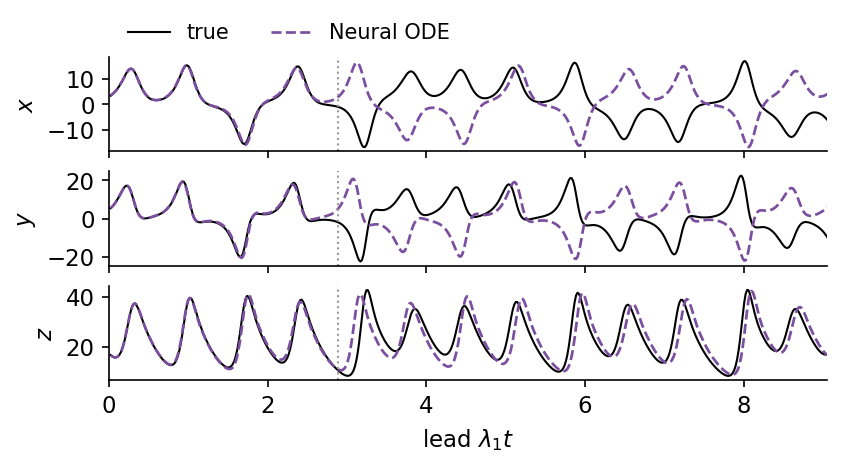

In [17]:
i_show = int(np.argmin(np.abs(res["Neural ODE"]["t_div"] - res["Neural ODE"]["t_div_med"])))   # an origin with the median divergence time
P_show = np.asarray(forecast_node(p_lor, Zj[K_TEST[i_show]][None]))[0] * SD_L + MU_L
T_show = U_L[K_TEST[i_show] + 1: K_TEST[i_show] + HOR + 1]
lead = LAM_TRUE * DT_L * np.arange(1, HOR + 1)                 # lead in Lyapunov times
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(3, 1, figsize=(5.5, 3.0), layout="constrained", sharex=True)
    for j, (ax, lab) in enumerate(zip(axs, ("$x$", "$y$", "$z$"))):
        ax.plot(lead, T_show[:, j], color="k", lw=1.0, label="true")
        ax.plot(lead, P_show[:, j], "--", color=STYLE["Neural ODE"]["color"], lw=1.3, label="Neural ODE")
        ax.axvline(res["Neural ODE"]["t_div"][i_show] * LAM_TRUE, color="0.6", ls=":", lw=1.0)
        ax.set_ylabel(lab)
    axs[-1].set_xlabel(r"lead $\lambda_1 t$"); axs[-1].set_xlim(0, lead[-1])
    axs[0].legend(loc="lower left", ncol=2, fontsize=10, bbox_to_anchor=(0, 0.95))
    save(fig, "fig_lab042_lorenz_forecast"); plt.show()
print(f"test origin {K_TEST[i_show]}: divergence time {res['Neural ODE']['t_div'][i_show]:.2f} time units")

The forecast follows all three coordinates for almost three Lyapunov times. The divergence starts where the true trajectory passes between the two lobes and switches to the lobe with negative $x$, while the forecast stays on the lobe with positive $x$. From then on $x$ and $y$ have opposite signs in the two trajectories, and $z$, which takes similar values on both lobes, keeps a similar shape with a shifted phase.

The learned flow can also be run far beyond the forecast horizon. A trajectory of 400 time units, started from the first test state, shows whether the learned vector field reproduces the attractor as a whole. The figure compares its projection on the $(x,z)$ plane with the 8000 data samples.

free run of 400 time units: finite True; mean z true 23.42, learned 23.57; std of x true 7.89, learned 7.88


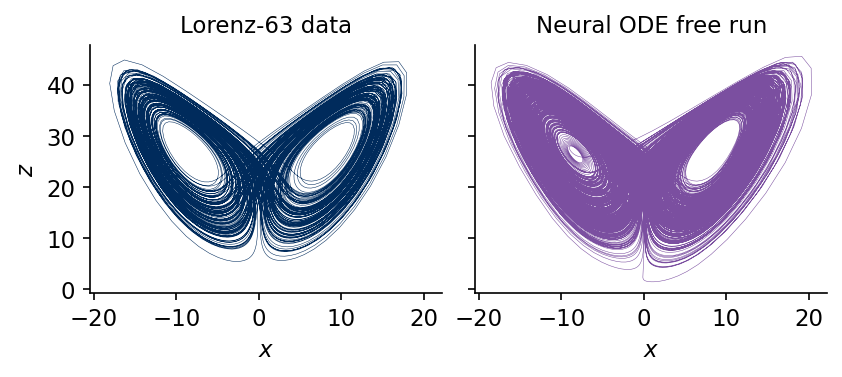

In [18]:
# long free run of the learned flow from the first test state, compared with the true attractor
n_long = 20000
Z_free = np.asarray(jax.jit(lambda z: node_flow(p_lor, z, n_long))(Zj[N_FIT + N_VAL]))
U_free = Z_free * SD_L + MU_L
ok = np.all(np.isfinite(U_free))
print(f"free run of {n_long * DT_L:g} time units: finite {ok}; mean z true {U_L[:, 2].mean():.2f}, learned {U_free[:, 2].mean():.2f};"
      f" std of x true {U_L[:, 0].std():.2f}, learned {U_free[:, 0].std():.2f}")
nums["free_run"] = dict(mean_z_true=float(U_L[:, 2].mean()), mean_z_node=float(U_free[:, 2].mean()),
                        std_x_true=float(U_L[:, 0].std()), std_x_node=float(U_free[:, 0].std()))
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained", sharex=True, sharey=True)
    axs[0].plot(U_L[:, 0], U_L[:, 2], color=UJNavy, lw=0.25); axs[0].set_title("Lorenz-63 data")
    axs[1].plot(U_free[:, 0], U_free[:, 2], color=STYLE["Neural ODE"]["color"], lw=0.25); axs[1].set_title("Neural ODE free run")
    for ax in axs: ax.set_xlabel("$x$")
    axs[0].set_ylabel("$z$")
    save(fig, "fig_lab042_lorenz_attractor"); plt.show()

The free run stays finite over 400 time units and fills both lobes. Its mean of $z$, 23.57, and its standard deviation of $x$, 7.88, are close to the values 23.42 and 7.89 of the data. The learned attractor contains a dense set of turns near the centre of the left lobe that the data do not show, so the long-time statistics of the learned flow are close to the true ones without being identical.

<hr/>
## 5. Irregular sampling

Measurements are often taken at irregular times, because of missed readings, event-driven recording or several instruments. A discrete-time model $\mathbf z_{k+1}=G(\mathbf z_k)$ assumes a fixed interval between its input and its output. A Neural ODE integrates the learned vector field over any interval, so irregular data require only a solver that stops at the observation times, and the model itself stays the same [Y. Rubanova, R. T. Q. Chen, D. Duvenaud, NeurIPS 2019, [arXiv:1907.03907](https://arxiv.org/abs/1907.03907)].

We repeat the pendulum experiment with irregular observation times. Each of the eight training trajectories is observed at $t=0$ and at 100 times drawn uniformly on $(0,10]$, the same number of observations as on the regular grid, with the same noise. The noise-free states at these times come from the adaptive Tsit5 solver of diffrax at tolerance $10^{-10}$.

In [19]:
# irregular observation times: t = 0 and 100 further times drawn uniformly on (0, 10], sorted
rng = np.random.default_rng(2)
T_IRR = np.stack([np.concatenate([[0.0], np.sort(rng.uniform(0, T_TRAIN, N_S))]) for _ in range(N_TRAJ)])   # (8, 101)
GAPS = np.diff(T_IRR, axis=1)                                                                               # (8, 100)
def true_at(y0, ts):
    sol = diffrax.diffeqsolve(diffrax.ODETerm(lambda t, y, args: f_dp(y)), diffrax.Tsit5(), 0.0, float(ts[-1]), 0.01,
                              jnp.asarray(y0), saveat=diffrax.SaveAt(ts=jnp.asarray(ts)),
                              stepsize_controller=diffrax.PIDController(rtol=1e-10, atol=1e-10), max_steps=100000)
    return np.asarray(sol.ys)
X_irr = np.stack([true_at(y0, ts) for y0, ts in zip(IC_TRAIN, T_IRR)])
Y_irr = X_irr + SIG_P * rng.normal(size=X_irr.shape)
# check the diffrax reference against our RK4 on the regular grid of the first trajectory
print(f"max |diffrax Tsit5 - RK4| on the regular grid: {np.abs(true_at(IC_TRAIN[0], DT_OBS * np.arange(N_S + 1)) - X_true[0]).max():.1e}")
print(f"gaps between observations: mean {GAPS.mean():.3f}, smallest {GAPS.min():.1e}, largest {GAPS.max():.3f}")
nums["irr"] = dict(gap_mean=float(GAPS.mean()), gap_min=float(GAPS.min()), gap_max=float(GAPS.max()))

max |diffrax Tsit5 - RK4| on the regular grid: 5.1e-10
gaps between observations: mean 0.099, smallest 2.1e-04, largest 0.712


The gaps between consecutive observations have the mean 0.099, the smallest $2.1\times10^{-4}$ and the largest 0.712. On the regular grid the diffrax reference agrees with our RK4 to $5.1\times10^{-10}$.

We compare four models, with the Neural ODE of Section 3, trained on the regular grid, as the reference. The second Neural ODE has the same architecture and training, and every interval of a segment is integrated with four RK4 steps of size (gap)/4. The two discrete-time models are MLPs of the same size, trained on the 800 consecutive pairs $(\mathbf y_k,\mathbf y_{k+1})$ of the irregular data with the one-step loss $\|\mathbf y_k+G(\cdot)-\mathbf y_{k+1}\|^2$. The first map receives the gap $t_{k+1}-t_k$ as a third input, $G(\mathbf y_k,t_{k+1}-t_k)$, the second only the state, $G(\mathbf y_k)$. All four forecast the three test trajectories up to $t=30$ on a regular grid with step 0.1, the mean gap of the training data, and the models that know the time also with step 0.25, which is larger than most gaps of the training data. The score is the root-mean-square error of $\theta$ over the forecast, averaged over the three test states.

In [20]:
N_SUB_IRR = 4                                        # RK4 steps per observation interval, of size gap/4
Yi_j, Gi_j = jnp.asarray(Y_irr), jnp.asarray(GAPS)
def node_gaps(p, x0, gaps):
    # Neural ODE through a sequence of intervals of different lengths
    def one(x, g):
        x = jax.lax.fori_loop(0, N_SUB_IRR, lambda i, v: rk4_step(lambda y: mlp(p, y), v, g / N_SUB_IRR), x)
        return x, x
    return jax.lax.scan(one, x0, gaps)[1]
def loss_irr(p, batch):
    i, j = batch
    pred = jax.vmap(lambda ii, jj: node_gaps(p, Yi_j[ii, jj], jax.lax.dynamic_slice_in_dim(Gi_j[ii], jj, SEG)))(i, j)
    tgt = jax.vmap(lambda ii, jj: jax.lax.dynamic_slice_in_dim(Yi_j[ii], jj + 1, SEG))(i, j)
    return jnp.mean((pred - tgt)**2)
p_irr, h_irr = train_adam(loss_irr, init_mlp(jax.random.key(0), [2, WIDTH_P, WIDTH_P, 2]), sampler_p, steps=3000, lr=3e-3)
print(f"Neural ODE on irregular samples: {h_irr['time']:.0f} s, final loss {h_irr['final']:.2e}")

# discrete-time maps trained on the consecutive pairs (y_k, y_{k+1}) of the same irregular data
X_in = Y_irr[:, :-1].reshape(-1, 2); X_out = Y_irr[:, 1:].reshape(-1, 2); G_in = GAPS.reshape(-1, 1)
def train_map(with_gap, seed=0, steps=3000):
    n_in = 3 if with_gap else 2
    Xi, Xo, Gi = jnp.asarray(X_in), jnp.asarray(X_out), jnp.asarray(G_in)
    def loss(p, idx):
        inp = jnp.concatenate([Xi[idx], Gi[idx]], 1) if with_gap else Xi[idx]
        return jnp.mean((Xi[idx] + jax.vmap(lambda u: mlp(p, u))(inp) - Xo[idx])**2)
    sampler = lambda key: jax.random.randint(key, (BATCH,), 0, Xi.shape[0])
    return train_adam(loss, init_mlp(jax.random.key(seed), [n_in, WIDTH_P, WIDTH_P, 2]), sampler, steps, lr=3e-3, seed=seed)
p_map_gap, _ = train_map(True)
p_map_nogap, _ = train_map(False)

def iterate_map(p, x0, n, gap=None):
    def one(x, _):
        inp = jnp.concatenate([x, jnp.array([gap])]) if gap is not None else x
        x = x + mlp(p, inp); return x, x
    return jax.lax.scan(one, x0, None, length=n)[1]

irr_rows = {}
for name in ("Neural ODE, regular samples", "Neural ODE, irregular samples", "map with gap input", "map without gap input"):
    errs = []
    for dt_fc in (0.1, 0.25):
        n = int(round(T_FC / dt_fc)); ts = dt_fc * np.arange(1, n + 1)
        e = []
        for y0 in IC_TEST:
            tru = true_at(y0, np.concatenate([[0.0], ts]))[1:]
            x0 = jnp.asarray(y0)
            if name.startswith("Neural ODE"):
                pp = p_pend if "regular" in name and "irregular" not in name else p_irr
                pr = node_gaps(pp, x0, jnp.full(n, dt_fc))
            elif name == "map with gap input":
                pr = iterate_map(p_map_gap, x0, n, dt_fc)
            elif dt_fc == 0.1:
                pr = iterate_map(p_map_nogap, x0, n)       # the map has no notion of time, one step = one observation
            else:
                e.append(np.nan); continue                 # a map without time input has no forecast at another step
            e.append(float(np.sqrt(np.mean((np.asarray(pr)[:, 0] - tru[:, 0])**2))))
        errs.append(float(np.mean(e)))
    irr_rows[name] = errs
    print(f"{name:30s} RMS theta error over t <= 30, mean over the test states: dt = 0.1 {errs[0]:.3f}, dt = 0.25 {errs[1]:.3f}")
nums["irr_rows"] = irr_rows

Neural ODE on irregular samples: 147 s, final loss 1.90e-04
Neural ODE, regular samples    RMS theta error over t <= 30, mean over the test states: dt = 0.1 0.034, dt = 0.25 0.034
Neural ODE, irregular samples  RMS theta error over t <= 30, mean over the test states: dt = 0.1 0.033, dt = 0.25 0.033
map with gap input             RMS theta error over t <= 30, mean over the test states: dt = 0.1 0.115, dt = 0.25 0.172
map without gap input          RMS theta error over t <= 30, mean over the test states: dt = 0.1 0.193, dt = 0.25 nan


Trained on irregular samples, the Neural ODE reaches the RMS error 0.033 at both forecast steps, the same as the Neural ODE trained on the regular grid, 0.034. The map with the gap as input reaches 0.115 with step 0.1 and 0.172 with step 0.25, and the map without the gap 0.193 with step 0.1. The upper panel of the figure marks the irregular observation times of the first training trajectory (blue) and the regular grid (grey). The lower panel shows the first test trajectory and the forecasts with step 0.1 of the Neural ODE trained on irregular samples and of the two maps.

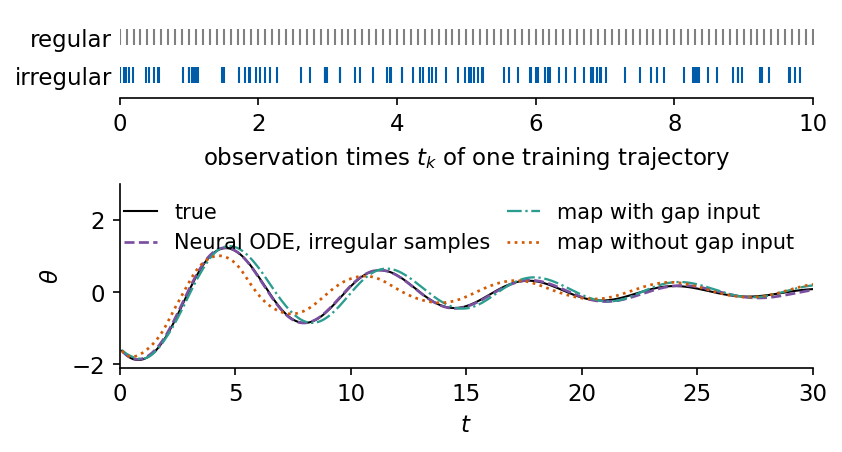

In [21]:
y0 = IC_TEST[0]
n = int(round(T_FC / 0.1)); ts = 0.1 * np.arange(1, n + 1)
tru = true_at(y0, np.concatenate([[0.0], ts]))[1:]
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(5.5, 2.9), layout="constrained", gridspec_kw={"height_ratios": [1, 2.2]})
    ax = axs[0]
    ax.plot(T_IRR[0], np.zeros(N_S + 1), "|", ms=8, color=UJBlue)
    ax.plot(DT_OBS * np.arange(N_S + 1), np.ones(N_S + 1), "|", ms=8, color="0.5")
    ax.set_yticks([0, 1]); ax.set_yticklabels(["irregular", "regular"]); ax.set_ylim(-0.6, 1.6); ax.set_xlim(0, T_TRAIN)
    ax.set_xlabel("observation times $t_k$ of one training trajectory")
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
    ax = axs[1]
    ax.plot(ts, tru[:, 0], color="k", lw=1.0, label="true")
    ax.plot(ts, np.asarray(node_gaps(p_irr, jnp.asarray(y0), jnp.full(n, 0.1)))[:, 0], "--", color=STYLE["Neural ODE"]["color"],
            lw=1.3, label="Neural ODE, irregular samples")
    ax.plot(ts, np.asarray(iterate_map(p_map_gap, jnp.asarray(y0), n, 0.1))[:, 0], "-.", color="#2A9D8F", lw=1.1,
            label="map with gap input")
    ax.plot(ts, np.asarray(iterate_map(p_map_nogap, jnp.asarray(y0), n))[:, 0], ":", color=DSOrange, lw=1.3,
            label="map without gap input")
    ax.set_xlim(0, T_FC); ax.set_ylim(-2.1, 3.0); ax.set_xlabel("$t$"); ax.set_ylabel(r"$\theta$")
    ax.legend(loc="upper right", ncol=2, fontsize=10, handlelength=1.6, columnspacing=0.8)
    save(fig, "fig_lab042_irregular"); plt.show()

The Neural ODE uses the irregular data without any change and loses nothing against regular sampling, because the solver integrates every interval with its own length and the learned field does not depend on the sampling. Its forecast does not depend on the output step either, since both steps sample the same integrated trajectory. The map with the gap as input has to learn how the step depends on the gap from 800 pairs whose gaps scatter between $2\times10^{-4}$ and 0.71. Its error is about three and a half times larger at step 0.1 and grows further at step 0.25, where it is iterated 120 times with a gap near the upper end of its training range. The map without the gap treats all intervals as equal, and its forecast runs with a wrong clock, ahead of the true oscillation. Both maps could be improved, for example with more data or with an architecture that builds in the dependence on the step, while the continuous-time model contains this dependence from the start.

<hr/>
## 6. Comparison with discrete-time models

We fit three discrete-time models to the Lorenz data of Section 4, with the same fitting block, the same validation choice of the settings and the same test origins and scores. Each of them predicts the next standardised state from the past ones and is iterated in a free run.

The AR model of order $p$ predicts the increment as a linear function of the last $p$ states, $\mathbf z_{k+1}-\mathbf z_k=W^\top\boldsymbol\phi_k+\mathbf b$ with $\boldsymbol\phi_k=(\mathbf z_k,\mathbf z_{k-1},\dots,\mathbf z_{k-p+1})\in\mathbb R^{3p}$. NVAR adds all products of two components of $\boldsymbol\phi_k$ to the features [D. J. Gauthier, E. Bollt, A. Griffith, W. A. S. Barbosa, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)]. The Lorenz vector field is a quadratic polynomial of the state, so for small $\Delta t$ the increment is close to a quadratic function of $\mathbf z_k$, and NVAR contains this function in its feature space. Both are fitted by ridge regression, which minimises $\sum_k\|\mathbf z_{k+1}-\mathbf z_k-W^\top\boldsymbol\phi_k-\mathbf b\|^2+\beta\|W\|^2$ and has the solution $W=(\Phi_c^\top\Phi_c+\beta I)^{-1}\Phi_c^\top Y_c$ with the centred feature matrix $\Phi_c$ and centred targets $Y_c$, so the intercept $\mathbf b$ is not penalised. The order $p$ and the ridge strength $\beta$ are chosen on the validation block from $p\in\{1,2,4,8,16\}$ for AR, $p\in\{1,2,3\}$ for NVAR and $\beta\in\{10^{-8},10^{-6},10^{-4},10^{-2}\}$.

In [22]:
def ridge_fit(Phi, Y, beta):
    # centred ridge regression, intercept unpenalised; Phi (n, d), Y (n, m)
    pm, ym = Phi.mean(0), Y.mean(0)
    W = jnp.linalg.solve((Phi - pm).T @ (Phi - pm) + beta * jnp.eye(Phi.shape[1]), (Phi - pm).T @ (Y - ym))
    return W, ym - pm @ W

def window(Z, ks, p):
    # rows (z_k, z_{k-1}, ..., z_{k-p+1}) flattened, shape (len(ks), 3p)
    return Z[ks[:, None] - np.arange(p)[None, :]].reshape(len(ks), -1)

def quad(lin):
    # all unique quadratic monomials of the linear features
    iu, ju = np.triu_indices(lin.shape[-1])
    return lin[..., iu] * lin[..., ju]

def features(kind, lin):
    return lin if kind == "AR" else jnp.concatenate([lin, quad(lin)], -1)

def fit_ridge_model(kind, p, beta):
    ks = np.arange(p - 1, N_FIT - 1)
    lin = jnp.asarray(window(Z_L, ks, p))
    Y = jnp.asarray(Z_L[ks + 1] - Z_L[ks])            # both models predict the increment z_{k+1} - z_k
    return ridge_fit(features(kind, lin), Y, beta)

def forecast_ridge(kind, W, b, p, ks):
    # free run: the window of the last p states is updated with every forecast
    def run(win):
        def one(win, _):
            z = win[0] + features(kind, win.reshape(-1)) @ W + b
            win = jnp.concatenate([z[None], win[:-1]], 0)
            return win, z
        return jax.lax.scan(one, win, None, length=HOR)[1]
    wins = jnp.asarray(Z_L[ks[:, None] - np.arange(p)[None, :]])
    return np.asarray(jax.jit(jax.vmap(run))(wins))

GRID = {"AR": dict(p=(1, 2, 4, 8, 16), beta=(1e-8, 1e-6, 1e-4, 1e-2)), "NVAR": dict(p=(1, 2, 3), beta=(1e-8, 1e-6, 1e-4, 1e-2))}
for kind in ("AR", "NVAR"):
    best = None
    for p in GRID[kind]["p"]:
        for beta in GRID[kind]["beta"]:
            W, b = fit_ridge_model(kind, p, beta)
            sc = scores(forecast_ridge(kind, W, b, p, K_VAL), TGT["val"])
            if best is None or sc["t_div_med"] > best[0]:
                best = (sc["t_div_med"], p, beta)
    _, p, beta = best
    W, b = fit_ridge_model(kind, p, beta)
    res[kind] = scores(forecast_ridge(kind, W, b, p, K_TEST), TGT["test"])
    res[kind].update(setting=f"p={p}, beta={beta:.0e}", n_par=int(W.size + b.size), W=W, b=b, p=p)
    print(f"{kind:5s} chosen p = {p}, beta = {beta:.0e} ({W.shape[0]} features, {W.size + b.size} coefficients);"
          f" validation {best[0] * LAM_TRUE:.2f}, test {res[kind]['lyap_med']:.2f} Lyapunov times")

# the same NVAR fit with scikit-learn
kind, p = "NVAR", res["NVAR"]["p"]
ks = np.arange(p - 1, N_FIT - 1)
Phi = np.asarray(features(kind, jnp.asarray(window(Z_L, ks, p))))
sk = SkRidge(alpha=float(res["NVAR"]["setting"].split("beta=")[1]), fit_intercept=True).fit(Phi, Z_L[ks + 1] - Z_L[ks])
# one-step predictions of the increment on the test block, JAX and scikit-learn
kt = np.arange(N_FIT + N_VAL, N_L - 1)
Phi_t = np.asarray(features(kind, jnp.asarray(window(Z_L, kt, p))))
d_pred = np.abs(Phi_t @ np.asarray(res["NVAR"]["W"]) + np.asarray(res["NVAR"]["b"]) - sk.predict(Phi_t)).max()
print(f"NVAR one-step increments on the test block: max |JAX - scikit-learn| = {d_pred:.1e},"
      f" typical increment size {np.abs(Z_L[kt + 1] - Z_L[kt]).mean():.1e}")
nums["ridge_check"] = float(d_pred)

AR    chosen p = 8, beta = 1e-08 (24 features, 75 coefficients); validation 0.24, test 0.24 Lyapunov times
NVAR  chosen p = 3, beta = 1e-08 (54 features, 165 coefficients); validation 7.68, test 7.69 Lyapunov times
NVAR one-step increments on the test block: max |JAX - scikit-learn| = 4.7e-09, typical increment size 1.2e-01


The validation chooses AR with $p=8$ and NVAR with $p=3$, both with the smallest ridge strength $10^{-8}$. NVAR then has 54 features, the 9 delayed components and their 45 products, and 165 coefficients including the intercepts. On the test block the AR free run diverges after 0.24 Lyapunov times in the median, and NVAR after 7.69. The one-step increments of our NVAR fit agree with scikit-learn to $4.7\times10^{-9}$, for a typical increment of 0.12.

The MLP map is the discrete-time counterpart of the Neural ODE. It predicts the next state from the present one as $\mathbf z_{k+1}=\mathbf z_k+G_\theta(\mathbf z_k)$, with an MLP $G_\theta$ of two tanh hidden layers, and it is trained on the one-step error over the fitting block with minibatches of 256 pairs and 4000 Adam steps. The width of the hidden layers, 32, 64 or 128, is chosen on the validation block.

In [23]:
def train_lorenz_map(width, steps=4000, batch=256, seed=0):
    # one-step map z_{k+1} = z_k + G(z_k), trained on the one-step error of the fit block
    Zin, Zout = Zj[:N_FIT - 1], Zj[1:N_FIT]
    def loss(p, idx):
        return jnp.mean((Zin[idx] + jax.vmap(lambda z: mlp(p, z))(Zin[idx]) - Zout[idx])**2)
    sampler = lambda key: jax.random.randint(key, (batch,), 0, N_FIT - 1)
    return train_adam(loss, init_mlp(jax.random.key(seed), [3, width, width, 3]), sampler, steps, lr=3e-3, seed=seed)

def map_free(p, z0, n):
    return jax.lax.scan(lambda z, _: ((z + mlp(p, z)),) * 2, z0, None, length=n)[1]
forecast_map = jax.jit(lambda p, Z0: jax.vmap(lambda z: map_free(p, z, HOR))(Z0))
map_runs = {}
for width in (32, 64, 128):
    p, h = train_lorenz_map(width)
    sc = scores(np.asarray(forecast_map(p, Zj[K_VAL])), TGT["val"])
    map_runs[width] = dict(p=p, h=h, val=sc)
    print(f"MLP map width {width:3d}: {h['time']:.0f} s, final loss {h['final']:.1e}, validation {sc['lyap_med']:.2f} Lyapunov times")
W_BEST = max(map_runs, key=lambda w: map_runs[w]["val"]["t_div_med"])
res["MLP map"] = scores(np.asarray(forecast_map(map_runs[W_BEST]["p"], Zj[K_TEST])), TGT["test"])
res["MLP map"].update(setting=f"width {W_BEST}", n_par=n_params(map_runs[W_BEST]["p"]), time=map_runs[W_BEST]["h"]["time"])
print(f"chosen width {W_BEST}; test {res['MLP map']['lyap_med']:.2f} Lyapunov times")

MLP map width  32: 3 s, final loss 8.5e-06, validation 2.12 Lyapunov times
MLP map width  64: 3 s, final loss 8.7e-06, validation 2.40 Lyapunov times
MLP map width 128: 7 s, final loss 7.9e-06, validation 2.60 Lyapunov times
chosen width 128; test 2.71 Lyapunov times


On the validation block the MLP maps of widths 32, 64 and 128 reach median divergence times of 2.12, 2.40 and 2.60 Lyapunov times, and we keep the width 128 with 17411 parameters. Each training takes a few seconds, since one step of the map costs one network evaluation and one RK4 step of the Neural ODE four.

The table collects the test scores of the four models, the chosen settings, the number of fitted parameters, the median divergence time in time units and in Lyapunov times, and the capacity $C(\tau)$ at the leads $\lambda_1\tau=1$, 2, 3 and 5.

In [24]:
LEADS = (1, 2, 3, 5)                                # leads in Lyapunov times for the table
idx_lead = [int(round(l / LAM_TRUE / DT_L)) - 1 for l in LEADS]
print(f"{'model':11s} {'setting':22s} {'params':>7s} {'median t_div':>13s} {'[Lyapunov]':>10s}" + "".join(f"{'C(' + str(l) + ')':>8s}" for l in LEADS))
for m in MODELS:
    r = res[m]
    print(f"{m:11s} {r['setting']:22s} {r['n_par']:7d} {r['t_div_med']:13.2f} {r['lyap_med']:10.2f}" + "".join(f"{r['C'][i]:8.3f}" for i in idx_lead))
nums["compare"] = {m: dict(setting=res[m]["setting"], n_par=res[m]["n_par"], t_div=res[m]["t_div_med"], lyap=res[m]["lyap_med"],
                           C={str(l): float(res[m]["C"][i]) for l, i in zip(LEADS, idx_lead)},
                           q25=float(np.percentile(res[m]["t_div"], 25) * LAM_TRUE), q75=float(np.percentile(res[m]["t_div"], 75) * LAM_TRUE))
                   for m in MODELS}

model       setting                 params  median t_div [Lyapunov]    C(1)    C(2)    C(3)    C(5)
AR          p=8, beta=1e-08             75          0.26       0.24   0.104   0.018   0.015   0.177
NVAR        p=3, beta=1e-08            165          8.49       7.69   1.000   1.000   1.000   0.997
MLP map     width 128                17411          2.99       2.71   0.986   0.875   0.566   0.118
Neural ODE  segment 10                4611          3.18       2.88   0.996   0.877   0.689   0.094


NVAR is the best model on these data by a wide margin. Its median divergence time is 7.69 Lyapunov times, with the interquartile range from 6.96 to 8.45, and its capacity stays at 1.00 up to $\lambda_1\tau=5$. The Neural ODE, with 2.88 (interquartile range 2.32 to 3.48), and the MLP map, with 2.71 (2.03 to 3.58), follow with overlapping distributions, and AR loses the trajectory after 0.24 Lyapunov times. The left panel of the figure shows the capacity curves $C(\tau)$ of the four models against the lead in Lyapunov times, with $C=0.5$ marked in grey. The right panel shows the distribution of the divergence times $\lambda_1t_{\rm div}$ over the test origins as box plots, with the box between the first and third quartile, the median as the black line and the whiskers reaching the most extreme values within 1.5 box lengths.

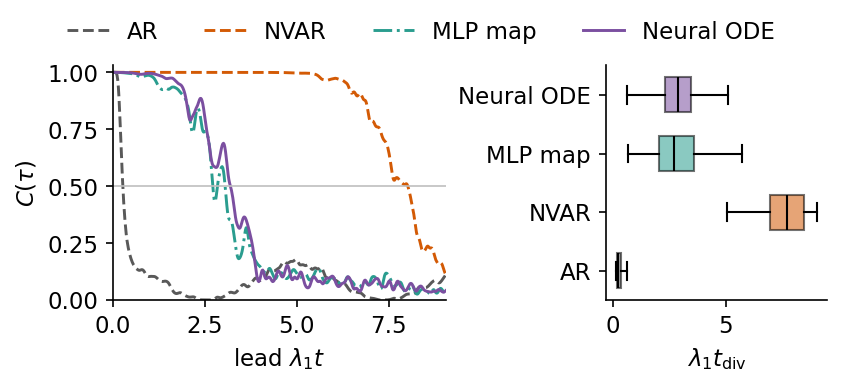

In [25]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.5), layout="constrained", gridspec_kw={"width_ratios": [1.5, 1]})
    for m in MODELS:
        axs[0].plot(lead, res[m]["C"], label=m, **STYLE[m])
    axs[0].axhline(0.5, color="0.75", lw=0.8)
    axs[0].set_xlabel(r"lead $\lambda_1 t$"); axs[0].set_ylabel(r"$C(\tau)$"); axs[0].set_xlim(0, lead[-1]); axs[0].set_ylim(0, 1.03)
    data = [res[m]["t_div"] * LAM_TRUE for m in MODELS]
    bp = axs[1].boxplot(data, orientation="horizontal", widths=0.6, patch_artist=True, showfliers=False, medianprops=dict(color="k"))
    for patch, m in zip(bp["boxes"], MODELS):
        patch.set_facecolor(STYLE[m]["color"]); patch.set_alpha(0.55)
    axs[1].set_yticks(range(1, len(MODELS) + 1)); axs[1].set_yticklabels(MODELS)
    axs[1].set_xlabel(r"$\lambda_1 t_{\rm div}$")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside upper center", ncol=4, handlelength=1.8)
    save(fig, "fig_lab042_lorenz_compare"); plt.show()

The ranking follows from the structure of the models. The Lorenz vector field is a quadratic polynomial, so over one sampling interval the flow map is close to a quadratic function of the state, which NVAR contains in its feature space and fits by a linear least-squares problem with a unique solution. The two networks must learn the quadratic terms with tanh units from 4000 samples by stochastic optimisation, and the accuracy of this fit limits their divergence time. The Neural ODE has about a quarter of the parameters of the MLP map and a slightly longer median divergence time, a difference smaller than the spread over the test origins, which a single training seed per model cannot resolve. AR is linear and cannot represent the switching between the two lobes. A system without a polynomial vector field, or with only part of the state measured, can change this ranking, and the results refer to the full Lorenz state, this protocol and the settings tested here.

<hr/>
## 7. Analysis of the learned vector field

A discrete-time model returns the next sample. The Neural ODE returns a vector field, an object of the same kind as the equations of motion, and the standard analysis of a dynamical system applies to it. We use three examples on the Lorenz model. The fixed points of $F_\theta$ are found by Newton's method, the iteration
$$\mathbf z\leftarrow\mathbf z-J(\mathbf z)^{-1}F_\theta(\mathbf z) \tag{21}$$
with the Jacobian from `jax.jacfwd`, started at the true fixed points. Their stability follows from the eigenvalues of the Jacobian, which we transform back to the physical coordinates,
$$J_{\mathbf u}={\rm diag}(\mathbf s)\,J_{\mathbf z}\,{\rm diag}(\mathbf s)^{-1}. \tag{22}$$
The trace of the Jacobian is the divergence of the learned flow, which we average over the test states and compare with the constant $-(\sigma+1+\beta)$.

In [26]:
def newton(fun, z, n_iter=50):
    for _ in range(n_iter):
        z = z - jnp.linalg.solve(jax.jacfwd(fun)(z), fun(z))
    return z
Fz = lambda z: F_L(p_lor, z)
fp_rows = []
for u in FP_TRUE:
    z = newton(Fz, jnp.asarray((u - MU_L) / SD_L))
    u_found = np.asarray(z) * SD_L + MU_L
    # Jacobian of du/dt = SD * F(z) in the original coordinates: diag(SD) J_z diag(1/SD)
    J = np.diag(SD_L) @ np.asarray(jax.jacfwd(Fz)(z)) @ np.diag(1 / SD_L)
    ev_l = np.sort_complex(np.linalg.eigvals(J))
    ev_t = np.sort_complex(np.linalg.eigvals(np.asarray(jax.jacfwd(lorenz_rhs)(jnp.asarray(u)))))
    fp_rows.append(dict(true=u.tolist(), found=u_found.tolist(), ev_true=ev_t, ev_learned=ev_l, res=float(jnp.linalg.norm(Fz(z)))))
    print(f"true {np.round(u, 2)} -> learned {np.round(u_found, 2)}, |F_theta| = {fp_rows[-1]['res']:.1e}")
    print(f"    eigenvalues true {np.round(ev_t, 2)}\n    eigenvalues learned {np.round(ev_l, 2)}")
# divergence of the flow (trace of the Jacobian) averaged over the data, true value -(sigma + 1 + beta)
tr = jax.vmap(lambda z: jnp.trace(jax.jacfwd(Fz)(z)))(Zj[N_FIT + N_VAL:])
print(f"mean divergence of the learned field on the test states {float(tr.mean()):.2f} (std {float(tr.std()):.2f}),"
      f" true -(sigma + 1 + beta) = {-(SIGMA_L + 1 + BETA_L):.2f}")
nums["fixed_points"] = [dict(true=r["true"], found=r["found"], ev_true=[[float(e.real), float(e.imag)] for e in r["ev_true"]],
                             ev_learned=[[float(e.real), float(e.imag)] for e in r["ev_learned"]]) for r in fp_rows]
nums["divergence"] = dict(learned=float(tr.mean()), std=float(tr.std()), true=-(SIGMA_L + 1 + BETA_L))

true [0. 0. 0.] -> learned [-0.3  -0.02  0.88], |F_theta| = 1.8e-15
    eigenvalues true [-22.83+0.j  -2.67+0.j  11.83+0.j]
    eigenvalues learned [-13.53+0.j  -3.27+0.j  11.03+0.j]
true [ 8.49  8.49 27.  ] -> learned [ 8.44  8.64 27.46], |F_theta| = 3.1e-15
    eigenvalues true [-13.85 +0.j     0.09-10.19j   0.09+10.19j]
    eigenvalues learned [-17.3 +0.j    -0.33-9.72j  -0.33+9.72j]
true [-8.49 -8.49 27.  ] -> learned [-8.31 -8.46 26.42], |F_theta| = 2.2e-15
    eigenvalues true [-13.85 +0.j     0.09-10.19j   0.09+10.19j]
    eigenvalues learned [-12.94 +0.j    0.15-10.2j   0.15+10.2j]
mean divergence of the learned field on the test states -13.88 (std 4.31), true -(sigma + 1 + beta) = -13.67


Newton's method converges from all three starting points, with $|F_\theta|$ below $4\times10^{-15}$ at the solutions. The learned origin lies at $(-0.30,-0.02,0.88)$ with the eigenvalues $-13.53$, $-3.27$ and $11.03$, against $-22.83$, $-2.67$ and $11.83$. It is a saddle with one unstable direction like the true origin, but its most contracting eigenvalue is off by about 40%. The learned $C_-$ at $(-8.31,-8.46,26.42)$ has the eigenvalues $-12.94$ and $0.15\pm10.20\,i$, an unstable spiral close to the true $0.094\pm10.195\,i$. The learned $C_+$ at $(8.44,8.64,27.46)$ has the complex pair $-0.33\pm9.72\,i$, so it is a stable spiral, while the true $C_+$ is weakly unstable. The real part of the complex pair, about one percent of its imaginary part, decides the stability, and the data, which never stay near the fixed points, determine it poorly. The learned flow therefore has an attracting state that the true system does not have, although the free run of Section 4 did not reach it within 400 time units. The mean divergence of $F_\theta$ on the test states, $-13.88$ with a standard deviation of 4.31 over the states, is close to the constant $-13.67$ of the Lorenz flow.

The largest Lyapunov exponent of the learned flow follows from the same Benettin procedure applied to one RK4 step of $F_\theta$ with $h=\Delta t=0.02$, over 1000 time units. Lyapunov exponents do not change under a linear change of coordinates, so the value in standardised coordinates can be compared with the true one directly.

In [27]:
t0 = time.time()
LAM_NODE, LAM_NODE_ERR = lyap_max(jax.jit(lambda z: rk4_step(lambda y: F_L(p_lor, y), z, DT_L)), Zj[N_FIT], 50000, DT_L)
print(f"lambda_1 of the learned flow = {LAM_NODE:.3f} +- {LAM_NODE_ERR:.3f} (true {LAM_TRUE:.3f} +- {LAM_TRUE_ERR:.3f}),"
      f" {time.time() - t0:.0f} s")
nums["lyap_node"] = dict(lam=LAM_NODE, err=LAM_NODE_ERR)

lambda_1 of the learned flow = 0.899 +- 0.010 (true 0.906 +- 0.007), 2 s


The learned flow has $\lambda_1=0.899\pm0.010$, which agrees with the true value $0.906\pm0.007$ within the standard errors. The learned field separates nearby states at the true rate, and the divergence of its forecasts reflects the errors of the field amplified by this rate.

The learned vector field also defines the state at every time between the samples it was trained on. We integrate $F_\theta$ with the adaptive Tsit5 solver from the first test state, save the state every 0.01 time units over half a time unit, and compare it with the true trajectory at the sample times $t=0.02\,n$ and halfway between them.

In [28]:
# forecasts between the samples: the learned flow evaluated by diffrax at times t = k * 0.01, every second one between samples
k0 = K_TEST[0]
n_half = 50                                         # 0.5 time units
true_fine = np.asarray(rk4_path(lorenz_rhs, jnp.asarray(U_L[k0]), H_L, n_half, 1))       # truth every 0.01
ts_fine = H_L * jnp.arange(1, n_half + 1)
sol = diffrax.diffeqsolve(diffrax.ODETerm(lambda t, z, args: F_L(p_lor, z)), diffrax.Tsit5(), 0.0, float(ts_fine[-1]), 0.01,
                          Zj[k0], saveat=diffrax.SaveAt(ts=ts_fine), stepsize_controller=diffrax.PIDController(rtol=1e-8, atol=1e-8))
pred_fine = np.asarray(sol.ys) * SD_L + MU_L
err_fine = np.linalg.norm(pred_fine - true_fine, axis=1)
print(f"mean error over 0.5 time units: at the sample times {err_fine[1::2].mean():.3f}, between the samples {err_fine[0::2].mean():.3f}"
      f" (attractor std of x {U_L[:, 0].std():.2f})")
nums["dense"] = dict(at=float(err_fine[1::2].mean()), between=float(err_fine[0::2].mean()))

mean error over 0.5 time units: at the sample times 0.240, between the samples 0.225 (attractor std of x 7.89)


The mean error over the first half time unit is 0.240 at the sample times and 0.225 between them, compared with the standard deviation 7.89 of $x$ on the attractor. The learned field is as accurate between the samples as at the samples. A discrete-time model has no output between its samples, and a forecast at a finer time step would require a new model.

<hr/>
## Learned dynamics and forecast accuracy

A Neural ODE learns the vector field $F_\theta$ of a dynamical system from measured trajectories. One Euler step has the form of a residual block, and in the limit of small steps a residual network with shared weights becomes the ODE of equation (1), whose forward pass is an ODE solver. The gradient of the trajectory loss can be computed by backpropagation through the solver or by integrating the adjoint equation backwards. On the damped pendulum both agree to $4.2\times10^{-8}$ with 50 RK4 steps and converge to each other as $h^4$. Backpropagation needs memory in proportion to the number of steps, 13592 kB at 3200 steps, and the adjoint a constant 26 kB at about 1.5 times the computing time, and diffrax reproduces both gradients.

On the damped pendulum, eight noisy trajectories suffice to learn the vector field with a median relative error of 0.012 in the region covered by the data and to forecast three times beyond the training window with a deviation of $\theta$ below $8.2\times10^{-2}$. Away from the data, near the saddles, the learned field is unreliable. The same model trained on irregularly sampled data forecasts as well as the one trained on the regular grid, while a discrete-time map with the gap as input has an error about three and a half times larger.

On Lorenz-63 the Neural ODE forecasts the full state for a median of 2.88 Lyapunov times and reproduces the attractor statistics and the largest Lyapunov exponent, 0.899 against 0.906. Its learned fixed points lie close to the true ones, while the weak instability of the convection states is not resolved, and one of them is learned as stable. On these data NVAR, whose quadratic features match the quadratic Lorenz field, is better by a wide margin with 7.69 Lyapunov times, the Neural ODE and the MLP map are close to each other, and the linear AR model fails after 0.24. Unlike a discrete-time model, the Neural ODE provides a vector field defined at every state and time, with a Jacobian, fixed points, a divergence and Lyapunov exponents that can be compared with physics, and a natural treatment of irregular sampling. These results refer to the systems, data sizes and settings used here.

## References

- R. T. Q. Chen, Y. Rubanova, J. Bettencourt, D. Duvenaud, *Neural ordinary differential equations*, NeurIPS 2018, [arXiv:1806.07366](https://arxiv.org/abs/1806.07366)
- P. Kidger, *On Neural Differential Equations*, PhD thesis, University of Oxford (2021), [arXiv:2202.02435](https://arxiv.org/abs/2202.02435)
- K. He, X. Zhang, S. Ren, J. Sun, *Deep residual learning for image recognition*, [arXiv:1512.03385](https://arxiv.org/abs/1512.03385)
- W. E, *A proposal on machine learning via dynamical systems*, Commun. Math. Stat. **5**, 1 (2017), [doi:10.1007/s40304-017-0103-z](https://doi.org/10.1007/s40304-017-0103-z)
- E. Haber, L. Ruthotto, *Stable architectures for deep neural networks*, Inverse Probl. **34**, 014004 (2018), [arXiv:1705.03341](https://arxiv.org/abs/1705.03341)
- A. Gholami, K. Keutzer, G. Biros, *ANODE: unconditionally accurate memory-efficient gradients for neural ODEs*, [arXiv:1902.10298](https://arxiv.org/abs/1902.10298)
- Y. Rubanova, R. T. Q. Chen, D. Duvenaud, *Latent ODEs for irregularly-sampled time series*, NeurIPS 2019, [arXiv:1907.03907](https://arxiv.org/abs/1907.03907)
- E. N. Lorenz, *Deterministic nonperiodic flow*, J. Atmos. Sci. **20**, 130 (1963), [doi:10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2](https://doi.org/10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2)
- G. Benettin, L. Galgani, A. Giorgilli, J.-M. Strelcyn, *Lyapunov characteristic exponents for smooth dynamical systems and for Hamiltonian systems. A method for computing all of them. Part 1. Theory*, Meccanica **15**, 9 (1980), [doi:10.1007/BF02128236](https://doi.org/10.1007/BF02128236)
- D. J. Gauthier, E. Bollt, A. Griffith, W. A. S. Barbosa, *Next generation reservoir computing*, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)
- E. Hairer, S. P. Nørsett, G. Wanner, *Solving Ordinary Differential Equations I. Nonstiff Problems*, 2nd ed., Springer (1993), [doi:10.1007/978-3-540-78862-1](https://doi.org/10.1007/978-3-540-78862-1)
- Ch. Tsitouras, *Runge–Kutta pairs of order 5(4) satisfying only the first column simplifying assumption*, Comput. Math. Appl. **62**, 770 (2011), [doi:10.1016/j.camwa.2011.06.002](https://doi.org/10.1016/j.camwa.2011.06.002)
- D. P. Kingma, J. Ba, *Adam: a method for stochastic optimization*, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)

The numbers quoted in the text are collected in a JSON file and as LaTeX macros.

In [29]:
nums["runtime_s"] = round(time.time() - t_start, 1)
def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, np.ndarray): return to_py(o.tolist())
    if isinstance(o, complex): return [o.real, o.imag]
    return o
with open(f"{OUT}/numbers_lab042.json", "w") as fh:
    json.dump(to_py(nums), fh, indent=1)

def sci(x, d=1):
    m, e = f"{x:.{d}e}".split("e")
    return f"{m}\\times10^{{{int(e)}}}"
MODTAG = {"AR": "AR", "NVAR": "NVAR", "MLP map": "MLPmap", "Neural ODE": "NODE"}
LEADTAG = {1: "One", 2: "Two", 3: "Three", 5: "Five"}
STEPTAG = {50: "Fifty", 200: "TwoHundred", 800: "EightHundred", 3200: "ThreeThousandTwoHundred"}
macros = {}
macros["EulerSlope"] = f"{nums['euler']['slopes'][-1]:.2f}"
for r in nums["adjoint"]:
    t = STEPTAG[r["n_steps"]]
    macros[f"AdjVsBp{t}"] = sci(r["adj_vs_bp"])
    macros[f"MemBp{t}"] = f"{r['mem backprop through RK4'] / 1e3:.0f}"
    macros[f"MemAdj{t}"] = f"{r['mem own adjoint'] / 1e3:.0f}"
macros["PendParams"] = str(nums["pend_node"]["n_params"]); macros["PendTrainTime"] = f"{nums['pend_node']['time']:.0f}"
macros["PendFieldNear"] = f"{nums['pend_field']['err_near']:.3f}"; macros["PendFieldFar"] = f"{nums['pend_field']['err_far']:.2f}"
macros["PendErrInMax"] = sci(max(r["err_in"] for r in nums["pend_forecast"]))
macros["PendErrOutMax"] = sci(max(r["err_out"] for r in nums["pend_forecast"]))
macros["LyapTrue"] = f"{LAM_TRUE:.3f}"; macros["LyapTrueErr"] = f"{LAM_TRUE_ERR:.3f}"
macros["LyapNODE"] = f"{LAM_NODE:.3f}"; macros["LyapNODEErr"] = f"{LAM_NODE_ERR:.3f}"
macros["LyapTime"] = f"{T_LYAP:.2f}"
macros["SegBest"] = str(SEG_BEST)
for m in MODELS:
    c = nums["compare"][m]
    macros[f"Tdiv{MODTAG[m]}"] = f"{c['lyap']:.2f}"
    macros[f"Params{MODTAG[m]}"] = str(c["n_par"])
    for l in LEADS:
        macros[f"C{LEADTAG[l]}{MODTAG[m]}"] = f"{c['C'][str(l)]:.2f}"
for name, tag in (("Neural ODE, regular samples", "NODERegular"), ("Neural ODE, irregular samples", "NODEIrregular"),
                  ("map with gap input", "MapGap"), ("map without gap input", "MapNoGap")):
    macros[f"Irr{tag}PointOne"] = f"{nums['irr_rows'][name][0]:.3f}"
    if np.isfinite(nums["irr_rows"][name][1]):
        macros[f"Irr{tag}PointTwoFive"] = f"{nums['irr_rows'][name][1]:.3f}"
macros["DivLearned"] = f"{nums['divergence']['learned']:.2f}"; macros["DivTrue"] = f"{nums['divergence']['true']:.2f}"
macros["Runtime"] = f"{nums['runtime_s'] / 60:.1f}"
bad = [k for k in macros if not k.isalpha()]
assert not bad, bad
with open(f"{OUT}/nb_numbers_lab042.tex", "w") as fh:
    for k, val in macros.items():
        fh.write(f"\\newcommand{{\\labfortytwo{k}}}{{{val}}}\n")
print(f"{len(macros)} macros written; total runtime {nums['runtime_s'] / 60:.1f} min")

59 macros written; total runtime 11.6 min
